# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../data/first_batch/'
DEVICE_NUMBER = 3
#filename = 'df_TRB145-5_2022-10-01_2022-11-01.csv'

In [3]:
all_files = glob.glob(DATA_DIR + f"df_TRB145-{DEVICE_NUMBER}*.csv")


df_list = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=0, header=0)
    df_list.append(df)

df = pd.concat(df_list, axis=0, ignore_index=True)
del df_list
df

,result,table,_time,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,...,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3,timestamp
0,_result,0,2022-08-29 15:17:49+00:00,0.467,0.467,1.94,0.011,240.300003,0.936,1.011,...,0.027,0.027,0.15,0.002,241.300003,50.029999,1.00,0.93,0.99,29/08/2022 17:17:49
1,_result,0,2022-08-29 15:18:00+00:00,0.468,0.468,1.95,0.011,240.500000,0.896,0.970,...,0.027,0.027,0.15,0.003,241.500000,50.029999,1.00,0.92,0.99,29/08/2022 17:18:00
2,_result,0,2022-08-29 15:18:09+00:00,0.467,0.467,1.94,0.011,240.500000,0.894,0.969,...,0.027,0.027,0.15,0.003,241.300003,50.029999,1.00,0.92,0.99,29/08/2022 17:18:09
3,_result,0,2022-08-29 15:18:19+00:00,0.468,0.468,1.95,0.011,240.500000,0.895,0.970,...,0.027,0.027,0.14,0.002,241.000000,50.029999,1.00,0.92,0.99,29/08/2022 17:18:19
4,_result,0,2022-08-29 15:18:30+00:00,0.466,0.467,1.94,0.011,240.300003,0.891,0.966,...,0.027,0.027,0.15,0.002,241.100006,50.020000,1.00,0.92,1.00,29/08/2022 17:18:30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6262219,_result,0,2022-12-17 12:15:07+00:00,0.016,0.078,0.35,0.076,236.100006,0.199,0.214,...,0.085,0.085,0.38,0.005,240.399994,50.000000,0.21,0.93,1.00,17/12/2022 13:15:07
6262220,_result,0,2022-12-17 12:15:07.001000+00:00,0.017,0.078,0.35,0.076,236.100006,0.199,0.214,...,0.083,0.084,0.37,0.005,240.600006,50.009998,0.23,0.93,1.00,17/12/2022 13:15:07
6262221,_result,0,2022-12-17 12:15:08+00:00,0.016,0.077,0.35,0.076,236.000000,0.199,0.214,...,0.083,0.083,0.37,0.005,240.899994,50.020000,0.21,0.93,1.00,17/12/2022 13:15:08
6262222,_result,0,2022-12-17 12:15:10+00:00,0.017,0.078,0.35,0.076,236.100006,0.201,0.216,...,0.083,0.083,0.37,0.005,240.899994,50.009998,0.22,0.93,1.00,17/12/2022 13:15:10


In [4]:
df.describe()

,table,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,6262224.0,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06,6.262224e+06
mean,0.0,2.989341e-01,3.344877e-01,1.431162e+00,6.865114e-02,2.381475e+02,4.805319e-01,5.035782e-01,2.200351e+00,1.231851e-01,2.382849e+02,3.475813e-01,3.481856e-01,1.505222e+00,4.877955e-03,2.394373e+02,5.000846e+01,5.855950e-01,9.029412e-01,9.874962e-01
std,0.0,5.908153e-01,5.765509e-01,2.454674e+00,3.350506e-02,1.857015e+00,6.198378e-01,6.222949e-01,2.641673e+00,1.022621e-01,1.773131e+00,8.989127e-01,8.991292e-01,3.793787e+00,2.795286e-02,1.894395e+00,2.218590e-02,3.447227e-01,1.096358e-01,2.531086e-02
min,0.0,7.000000e-03,4.100000e-02,1.800000e-01,0.000000e+00,2.197000e+02,3.100000e-02,6.300000e-02,3.000000e-01,0.000000e+00,2.227000e+02,2.300000e-02,2.300000e-02,1.300000e-01,0.000000e+00,1.989000e+02,4.987000e+01,1.000000e-01,2.800000e-01,2.600000e-01
25%,0.0,1.800000e-02,7.600000e-02,3.400000e-01,6.000000e-02,2.370000e+02,1.490000e-01,1.690000e-01,7.800000e-01,6.900000e-02,2.371000e+02,2.700000e-02,2.700000e-02,1.500000e-01,1.000000e-03,2.382000e+02,4.999000e+01,2.500000e-01,8.800000e-01,9.900000e-01
50%,0.0,3.700000e-02,9.200000e-02,4.200000e-01,7.300000e-02,2.383000e+02,2.070000e-01,2.200000e-01,1.000000e+00,8.300000e-02,2.384000e+02,2.800000e-02,2.900000e-02,1.600000e-01,2.000000e-03,2.396000e+02,5.001000e+01,4.200000e-01,9.400000e-01,1.000000e+00
75%,0.0,4.580000e-01,4.590000e-01,1.930000e+00,8.200000e-02,2.395000e+02,4.600000e-01,4.650000e-01,2.080000e+00,1.030000e-01,2.395000e+02,4.100000e-02,4.100000e-02,2.200000e-01,6.000000e-03,2.408000e+02,5.002000e+01,1.000000e+00,9.700000e-01,1.000000e+00
max,0.0,8.407000e+00,8.407000e+00,3.686000e+01,1.617000e+00,2.456000e+02,8.177000e+00,8.395000e+00,4.101000e+01,1.899000e+00,2.461000e+02,7.176000e+00,7.176000e+00,3.051000e+01,2.446000e+00,2.460000e+02,5.014000e+01,1.000000e+00,1.000000e+00,1.000000e+00


# Data preprocessing

## Drop useless columns

In [5]:
display(df['result'].unique(), df['table'].unique())
df = df.drop(columns=['result', 'table'])

array(['_result'], dtype=object)

array([0])

In [6]:
df.columns

Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L2_act_power', 'L2_app_power', 'L2_current',
       'L2_react_power', 'L2_voltage', 'L3_act_power', 'L3_app_power',
       'L3_current', 'L3_react_power', 'L3_voltage', 'grid_freq',
       'powerfactor1', 'powerfactor2', 'powerfactor3', 'timestamp'],
      dtype='object')

Drop 0 std columns

In [7]:
cols_0_std = df.std(numeric_only=True)[df.std(numeric_only=True) == 0].index.values
print('Columns with 0 std:\n', cols_0_std)

df = df.drop(columns=cols_0_std)
print('\nColumns left:')
df.columns

Columns with 0 std:
 []

Columns left:


Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L2_act_power', 'L2_app_power', 'L2_current',
       'L2_react_power', 'L2_voltage', 'L3_act_power', 'L3_app_power',
       'L3_current', 'L3_react_power', 'L3_voltage', 'grid_freq',
       'powerfactor1', 'powerfactor2', 'powerfactor3', 'timestamp'],
      dtype='object')

Devices **#1** and **#2** have `std==0` for **L2/powerfactor2** and **L3/powerfactor3** features

`L3_voltage` has only 1 different value, so also drop it (in **device #2**)

In [8]:
try:
    display(df['L3_voltage'].value_counts())
    if df['L3_voltage'].value_counts().shape[0] < 3:
        print('L3_voltage has only one value, dropping it')
        df = df.drop(columns=['L3_voltage'])
except KeyError:
    print('L3_voltage not found in df (already deleted in the previous stage)')

L3_voltage
239.600006    144449
239.699997    142910
239.500000    141463
239.800003    140791
239.899994    139231
               ...  
245.800003         1
198.899994         1
213.199997         1
225.399994         1
226.300003         1
Name: count, Length: 180, dtype: int64

## Missing values (without filled seconds)

In [9]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
_time,6262224,0,0.0
L1_act_power,6262224,0,0.0
L1_app_power,6262224,0,0.0
L1_current,6262224,0,0.0
L1_react_power,6262224,0,0.0
L1_voltage,6262224,0,0.0
L2_act_power,6262224,0,0.0
L2_app_power,6262224,0,0.0
L2_current,6262224,0,0.0
L2_react_power,6262224,0,0.0


## Time-index

In [10]:
df[['_time', 'timestamp']]

,_time,timestamp
0,2022-08-29 15:17:49+00:00,29/08/2022 17:17:49
1,2022-08-29 15:18:00+00:00,29/08/2022 17:18:00
2,2022-08-29 15:18:09+00:00,29/08/2022 17:18:09
3,2022-08-29 15:18:19+00:00,29/08/2022 17:18:19
4,2022-08-29 15:18:30+00:00,29/08/2022 17:18:30
...,...,...
6262219,2022-12-17 12:15:07+00:00,17/12/2022 13:15:07
6262220,2022-12-17 12:15:07.001000+00:00,17/12/2022 13:15:07
6262221,2022-12-17 12:15:08+00:00,17/12/2022 13:15:08
6262222,2022-12-17 12:15:10+00:00,17/12/2022 13:15:10


`_time` issues:
- column has inconsistent time differences between rows;
- it's inconsistent with the `timestamp` column (they show different times for the same row);
- it takes to long to transform it to datetime. 

We decide to use the `timestamp` column as time index. We drop the `_time` column.

In [11]:
df = df.drop(columns=['_time'])

If looking at `timestamp`, the $1/3$ of data are duplicates

In [12]:
df['timestamp'].duplicated().sum()

np.int64(1962673)

We can **drop** the duplicates or merge them by taking the **mean**

We decide to take the **mean**

In [13]:
# merge duplicated 'timestamp' rows by taking the mean of all values
df = df.groupby('timestamp').mean().reset_index()
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
0,01/09/2022 00:00:06,0.023,0.089,0.40,0.086,239.699997,0.107,0.125,0.62,0.064,239.800003,0.028,0.028,0.15,0.001,240.500000,50.029999,0.27,0.86,1.0
1,01/09/2022 00:00:15,0.022,0.088,0.39,0.085,239.600006,0.108,0.125,0.62,0.063,239.699997,0.028,0.028,0.15,0.001,240.399994,50.020000,0.26,0.86,1.0
2,01/09/2022 00:00:24,0.022,0.088,0.39,0.085,239.500000,0.109,0.126,0.63,0.063,239.600006,0.028,0.029,0.15,0.001,240.300003,50.000000,0.25,0.86,1.0
3,01/09/2022 00:00:35,0.023,0.089,0.40,0.086,239.699997,0.105,0.123,0.61,0.063,239.800003,0.028,0.028,0.15,0.002,240.500000,49.980000,0.27,0.86,1.0
4,01/09/2022 00:00:44,0.023,0.089,0.39,0.086,239.699997,0.105,0.123,0.61,0.063,239.899994,0.028,0.028,0.15,0.001,240.600006,50.009998,0.26,0.85,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4299546,31/08/2022 23:59:15,0.024,0.089,0.40,0.086,239.800003,0.107,0.126,0.61,0.066,240.100006,0.028,0.028,0.15,0.001,240.800003,50.040001,0.27,0.85,1.0
4299547,31/08/2022 23:59:25,0.030,0.091,0.42,0.085,239.899994,0.109,0.127,0.61,0.065,240.100006,0.028,0.028,0.15,0.002,240.800003,50.029999,0.34,0.86,1.0
4299548,31/08/2022 23:59:36,0.023,0.089,0.40,0.086,239.899994,0.108,0.127,0.61,0.065,240.100006,0.028,0.028,0.15,0.001,240.800003,50.040001,0.26,0.86,1.0
4299549,31/08/2022 23:59:45,0.024,0.089,0.40,0.086,239.800003,0.109,0.127,0.62,0.065,240.000000,0.028,0.028,0.15,0.001,240.699997,50.029999,0.27,0.86,1.0


Transform `timestamp` to datetime and use as index

In [14]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%d/%m/%Y %H:%M:%S')
df = df.sort_values(by='timestamp')
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
2227014,2022-08-17 08:09:25,0.0190,0.080,0.36,0.078,235.899994,0.1550,0.167,0.770,0.059,236.300003,0.037,0.0370,0.190,0.0020,236.000000,49.980000,0.24,0.93,1.0
2227015,2022-08-17 08:09:30,0.0180,0.080,0.36,0.078,235.500000,0.1550,0.166,0.770,0.059,236.500000,0.037,0.0370,0.190,0.0020,236.199997,50.000000,0.23,0.93,1.0
2227016,2022-08-17 08:09:41,0.0200,0.080,0.36,0.078,235.800003,0.1550,0.166,0.770,0.060,236.600006,0.037,0.0370,0.190,0.0020,236.100006,50.000000,0.25,0.93,1.0
2227017,2022-08-17 08:09:50,0.0190,0.080,0.36,0.078,236.100006,0.1480,0.160,0.730,0.061,236.399994,0.036,0.0360,0.180,0.0020,236.100006,50.029999,0.24,0.92,1.0
2227018,2022-08-17 08:10:01,0.0180,0.080,0.36,0.078,235.800003,0.1520,0.164,0.750,0.060,236.600006,0.037,0.0370,0.190,0.0010,236.300003,50.009998,0.23,0.93,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2330793,2022-12-17 13:15:04,0.0165,0.078,0.35,0.076,236.449997,0.1995,0.214,0.995,0.078,237.849998,0.085,0.0850,0.380,0.0045,240.500000,50.009998,0.22,0.93,1.0
2330794,2022-12-17 13:15:05,0.0170,0.078,0.35,0.076,236.199997,0.1990,0.214,0.990,0.078,237.800003,0.084,0.0840,0.370,0.0050,240.399994,50.000000,0.22,0.93,1.0
2330795,2022-12-17 13:15:07,0.0165,0.078,0.35,0.076,236.100006,0.1990,0.214,1.000,0.078,237.800003,0.084,0.0845,0.375,0.0050,240.500000,50.004999,0.22,0.93,1.0
2330796,2022-12-17 13:15:08,0.0160,0.077,0.35,0.076,236.000000,0.1990,0.214,0.990,0.078,237.899994,0.083,0.0830,0.370,0.0050,240.899994,50.020000,0.21,0.93,1.0


## Time range

In [15]:
print('We have data from:', df['timestamp'].min(),
      '\nuntil:', df['timestamp'].max())


We have data from: 2022-08-17 08:09:25 
until: 2022-12-17 13:15:10


## Time frequency
1-2 seconds between rows

In [16]:
df['timestamp'].diff().describe()

count                      4299550
mean     0 days 00:00:02.455872126
std      0 days 00:07:30.406492481
min                0 days 00:00:01
25%                0 days 00:00:01
50%                0 days 00:00:02
75%                0 days 00:00:02
max                8 days 05:20:11
Name: timestamp, dtype: object

## Missing seconds?

In [17]:
df.groupby(df['timestamp'].dt.floor('min')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000,145927.000000
mean,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711,29.463711
std,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795,15.549795
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000,6.000000
50%,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000
75%,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000
max,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000


Only **39** seconds are available out of **60** on average for **each minute** for **devices #4** and **#5**!

In [18]:
df.groupby(df['timestamp'].dt.floor('h')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000,2444.000000
mean,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087,1759.227087
std,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978,933.086978
min,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
25%,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000
50%,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000,2378.000000
75%,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000,2394.000000
max,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000,3282.000000


2322 seconds present out of 60*60=3600 seconds in **device #4** and **#5** are missing
$$2322/3600=0.6455$$

In [19]:
df = df.set_index('timestamp')

In [20]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='s'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all seconds filled

In [21]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
L1_act_power,4299551,6259595,59.281262
L1_app_power,4299551,6259595,59.281262
L1_current,4299551,6259595,59.281262
L1_react_power,4299551,6259595,59.281262
L1_voltage,4299551,6259595,59.281262
L2_act_power,4299551,6259595,59.281262
L2_app_power,4299551,6259595,59.281262
L2_current,4299551,6259595,59.281262
L2_react_power,4299551,6259595,59.281262
L2_voltage,4299551,6259595,59.281262


**Device #3**
```
                total	missing	missing_perc
L1_act_power	4299551	6259595	59.281262
L1_app_power	4299551	6259595	59.281262
L1_current	    4299551	6259595	59.281262
L1_react_power	4299551	6259595	59.281262
L1_voltage	    4299551	6259595	59.281262
L2_act_power	4299551	6259595	59.281262
L2_app_power	4299551	6259595	59.281262
L2_current	    4299551	6259595	59.281262
L2_react_power	4299551	6259595	59.281262
L2_voltage	    4299551	6259595	59.281262
L3_act_power	4299551	6259595	59.281262
L3_app_power	4299551	6259595	59.281262
L3_current	    4299551	6259595	59.281262
L3_react_power	4299551	6259595	59.281262
L3_voltage	    4299551	6259595	59.281262
grid_freq	    4299551	6259595	59.281262
powerfactor1	4299551	6259595	59.281262
powerfactor2	4299551	6259595	59.281262
powerfactor3	4299551	6259595	59.281262
```

**Device #4**
```
total	        missing	    missing_perc
L1_act_power	12606408	9279732	42.400039
L1_app_power	12606408	9279732	42.400039
L1_current	    12606408	9279732	42.400039
L1_react_power	12606408	9279732	42.400039
L1_voltage	    12606408	9279732	42.400039
L2_act_power	12606408	9279732	42.400039
L2_app_power	12606408	9279732	42.400039
L2_current	    12606408	9279732	42.400039
L2_react_power	12606408	9279732	42.400039
L2_voltage	    12606408	9279732	42.400039
L3_act_power	12606408	9279732	42.400039
L3_app_power	12606408	9279732	42.400039
L3_current	    12606408	9279732	42.400039
L3_react_power	12606408	9279732	42.400039
L3_voltage	    12606408	9279732	42.400039
grid_freq	    12606408	9279732	42.400039
powerfactor1	12606408	9279732	42.400039
powerfactor2	12606408	9279732	42.400039
powerfactor3	12606408	9279732	42.400039
```

**Device #5**
```
                total	    missing	    missing_perc
L1_act_power	12605043	9280582	    42.404921
L1_app_power	12605043	9280582	    42.404921
L1_current	    12605043	9280582	    42.404921
L1_react_power	12605043	9280582	    42.404921
L1_voltage	    12605043	9280582	    42.404921
L2_act_power	12605043	9280582	    42.404921
L2_app_power	12605043	9280582	    42.404921
L2_current	    12605043	9280582	    42.404921
L2_react_power	12605043	9280582	    42.404921
L2_voltage	    12605043	9280582	    42.404921
L3_act_power	12605043	9280582	    42.404921
L3_app_power	12605043	9280582	    42.404921
L3_current	    12605043	9280582	    42.404921
L3_react_power	12605043	9280582	    42.404921
L3_voltage	    12605043	9280582	    42.404921
grid_freq	    12605043	9280582	    42.404921
powerfactor1	12605043	9280582	    42.404921
powerfactor2	12605043	9280582	    42.404921
powerfactor3	12605043	9280582	    42.404921
```

**42% missing values for device #4 and #5**

In [23]:
df = df.reset_index().rename(columns={'index': 'timestamp'})

# Data Analysis

## Correlation matrix

In [ ]:
sns.heatmap(df.drop(columns=['timestamp']).fillna('median').corr(), annot=True)
plt.title(f"Correlation Matrix")
plt.tight_layout()
plt.show()

## Feature Analysis by Phase

### L1 Phase Analysis

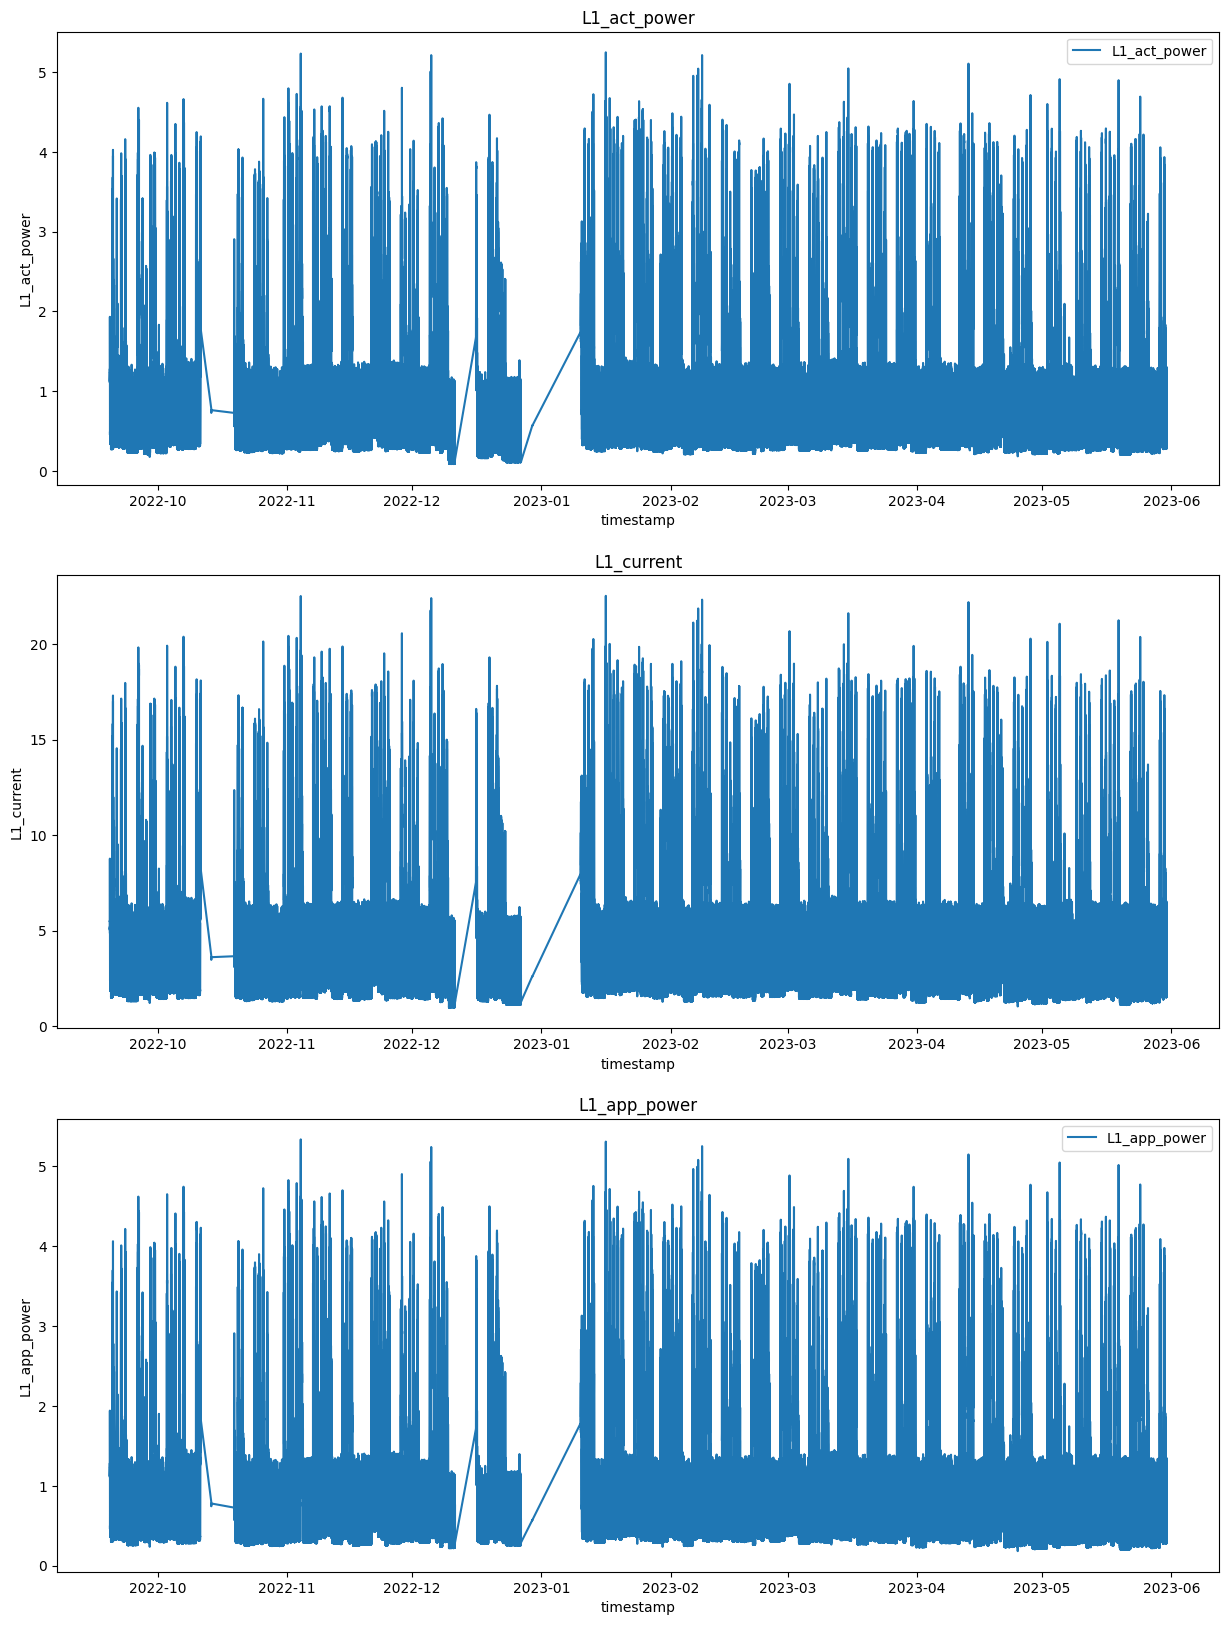

In [65]:
fig, axes = plt.subplots(3, 1, figsize=(15, 20))

sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1_act_power', ax=axes[0])
axes[0].set_title('L1_act_power')
sns.lineplot(data=df, x='timestamp', y='L1_current', ax=axes[1])
axes[1].set_title('L1_current')
sns.lineplot(data=df, x='timestamp', y='L1_app_power', label='L1_app_power', ax=axes[2])
axes[2].set_title('L1_app_power');

We have missing values from around **2022-10-12 until 2022-10-20** for **all devices**

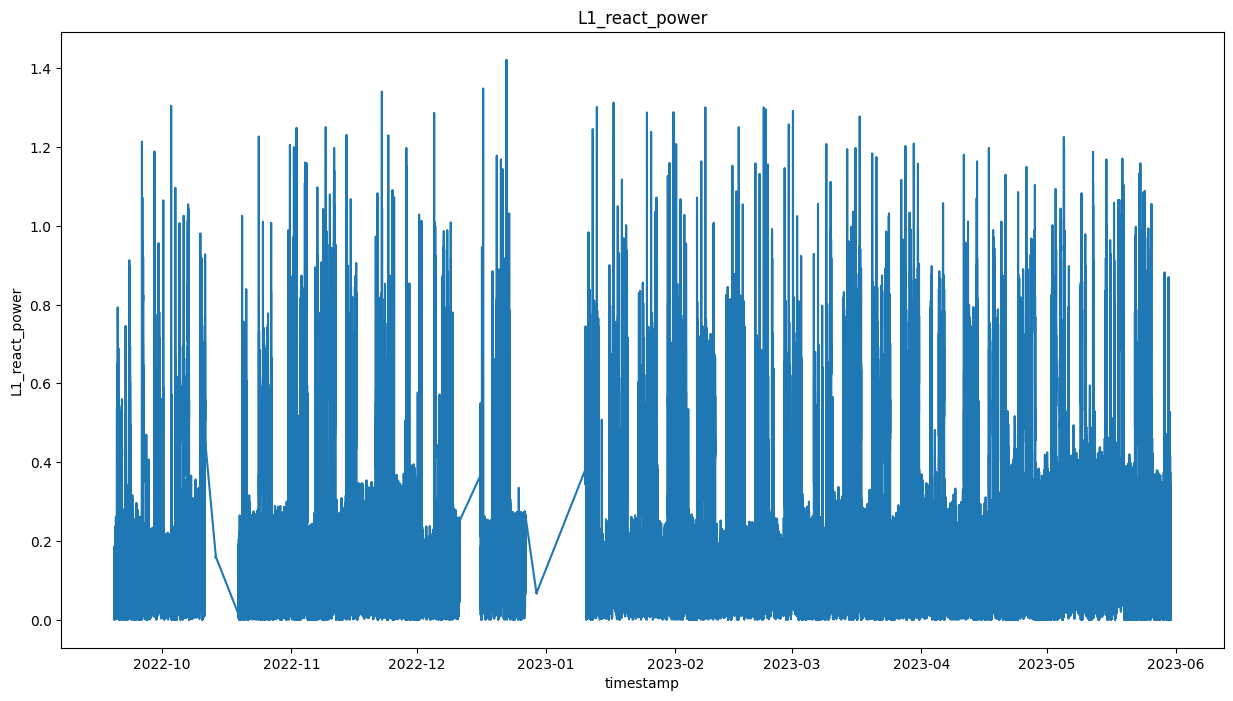

In [66]:
sns.lineplot(data=df, x='timestamp', y='L1_react_power')
plt.title('L1_react_power');

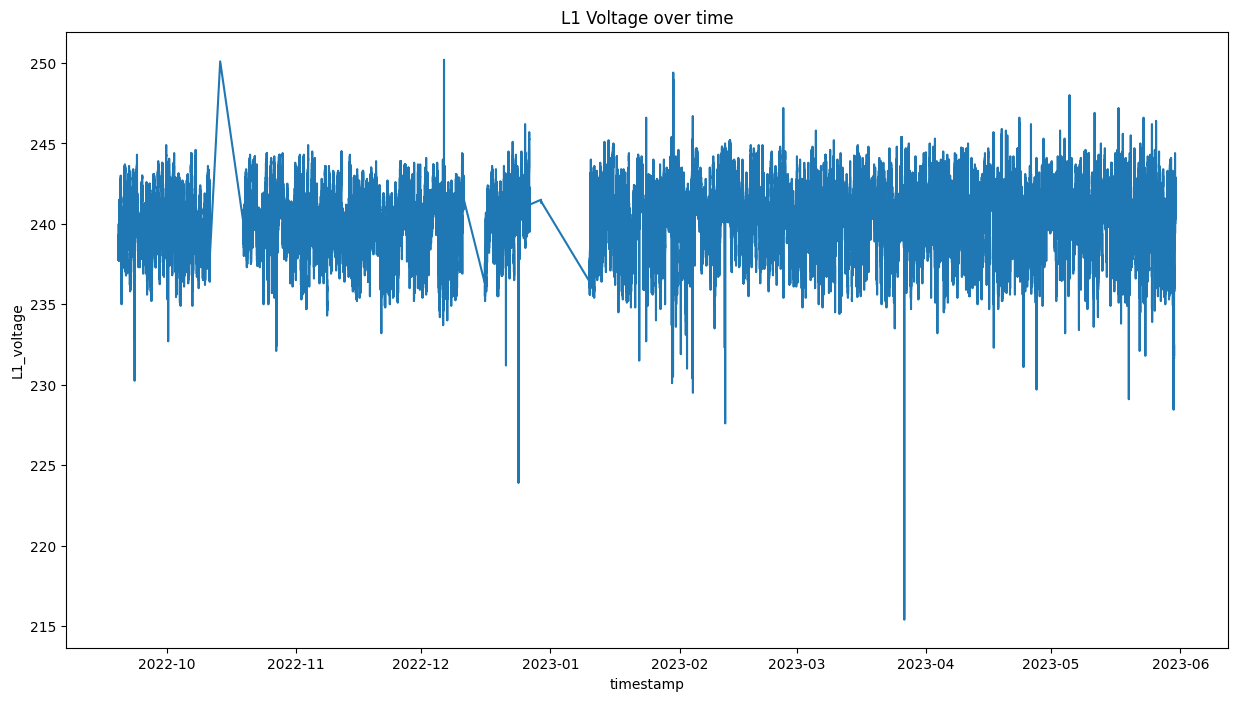

In [67]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage')
plt.title('L1 Voltage over time');

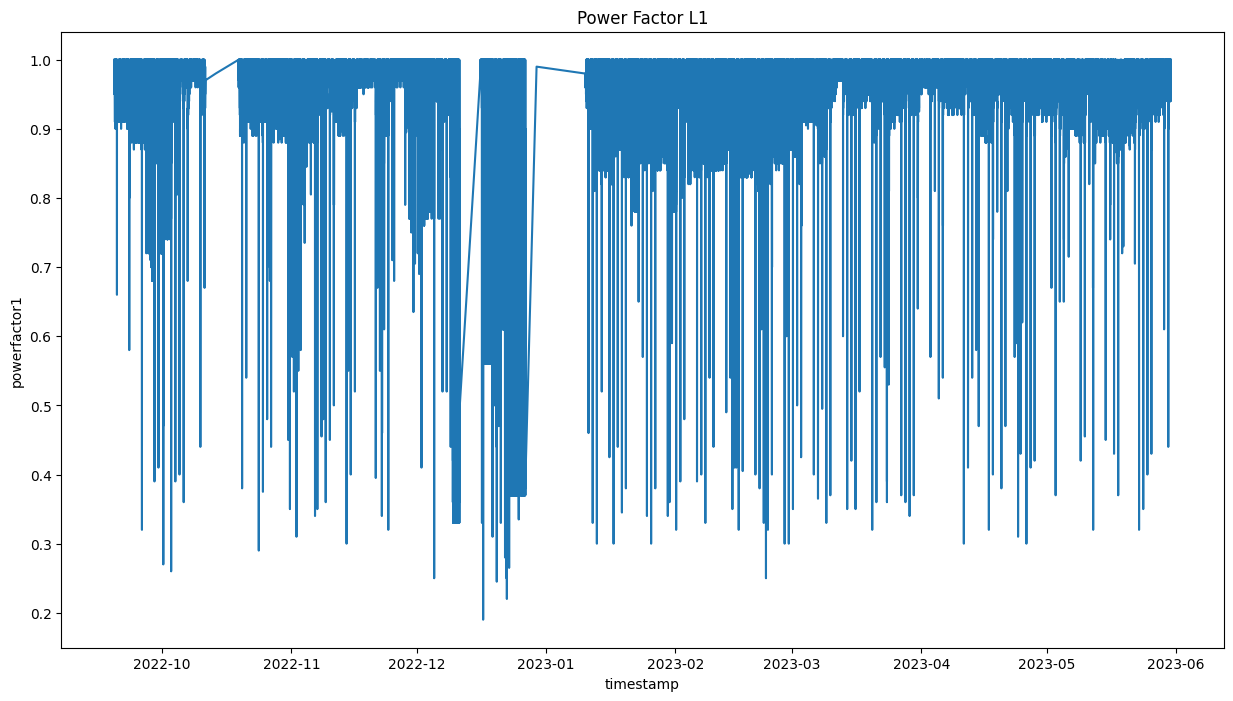

In [68]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1')
plt.title('Power Factor L1');

### L2 Phase Analysis

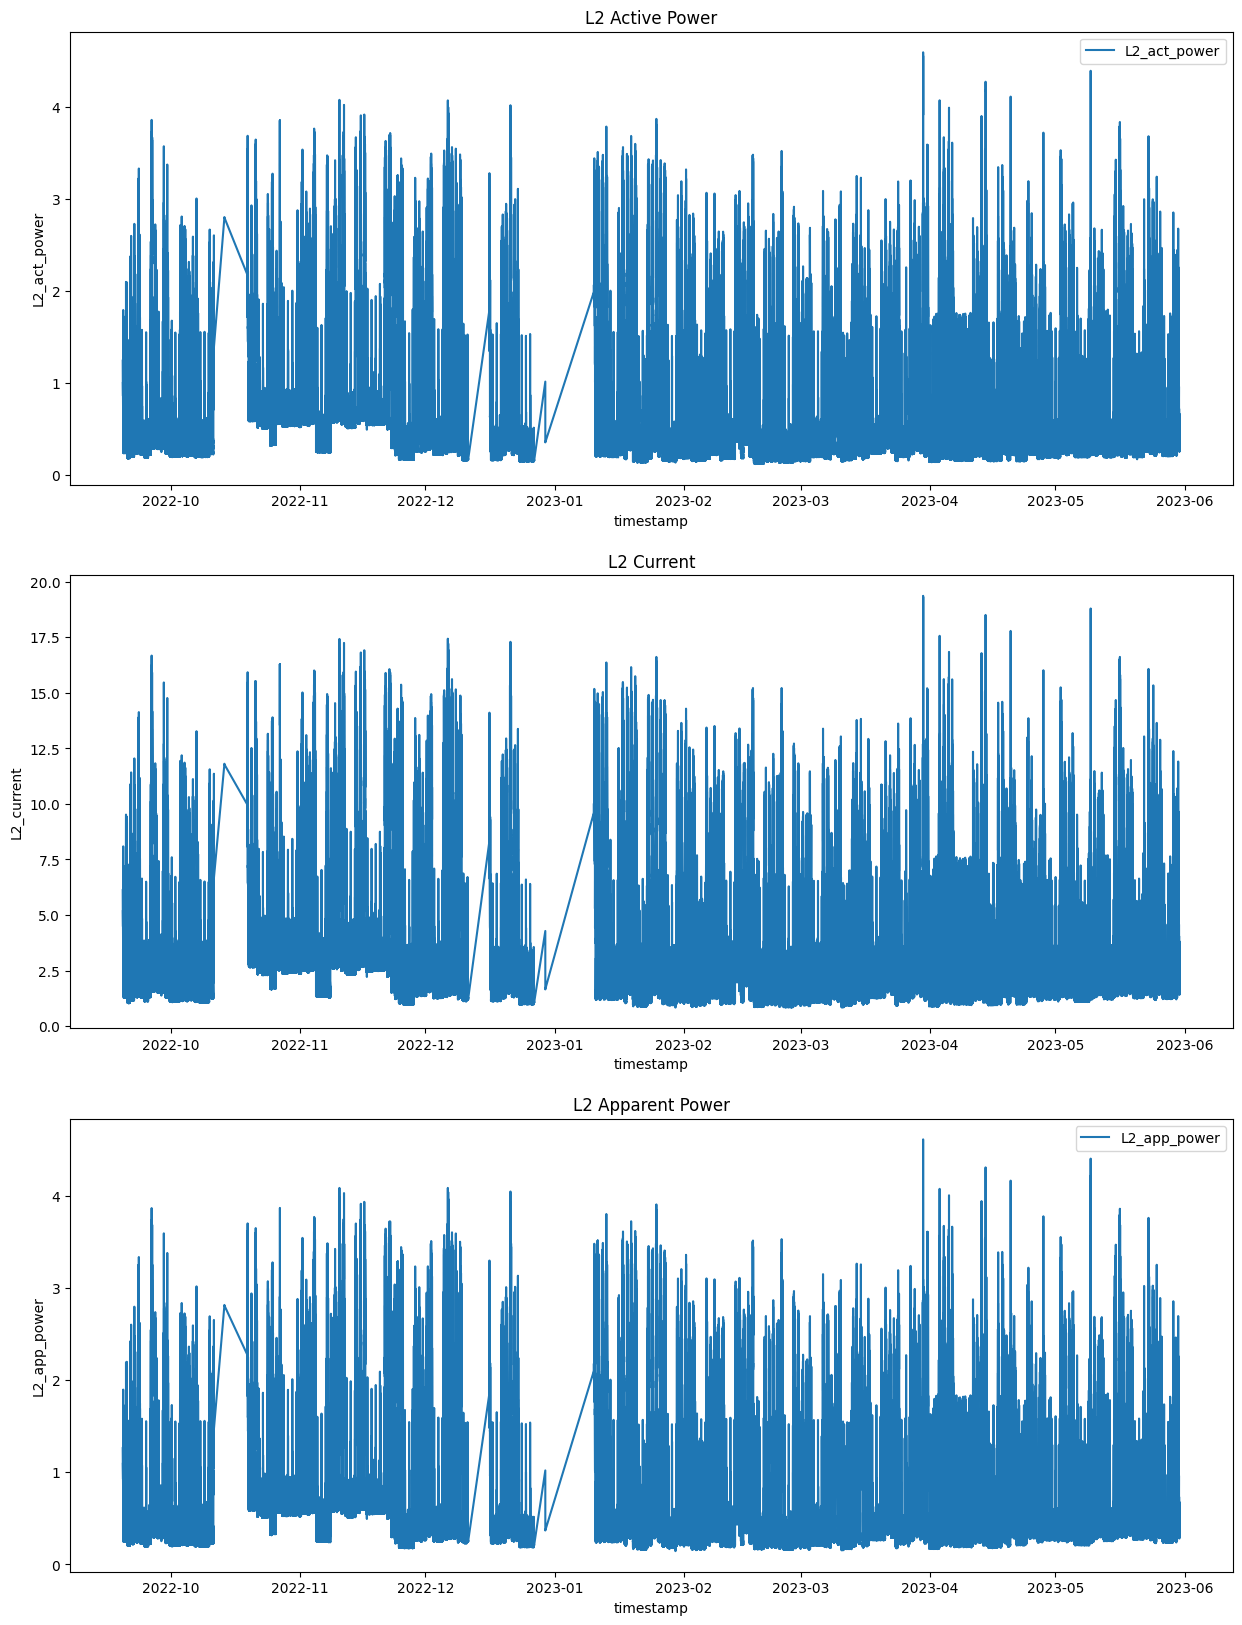

In [70]:
if df.columns.str.contains('L2').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2_act_power', ax=axes[0])
    axes[0].set_title('L2 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L2_current', ax=axes[1])
    axes[1].set_title('L2 Current')
    sns.lineplot(data=df, x='timestamp', y='L2_app_power', label='L2_app_power', ax=axes[2])
    axes[2].set_title('L2 Apparent Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

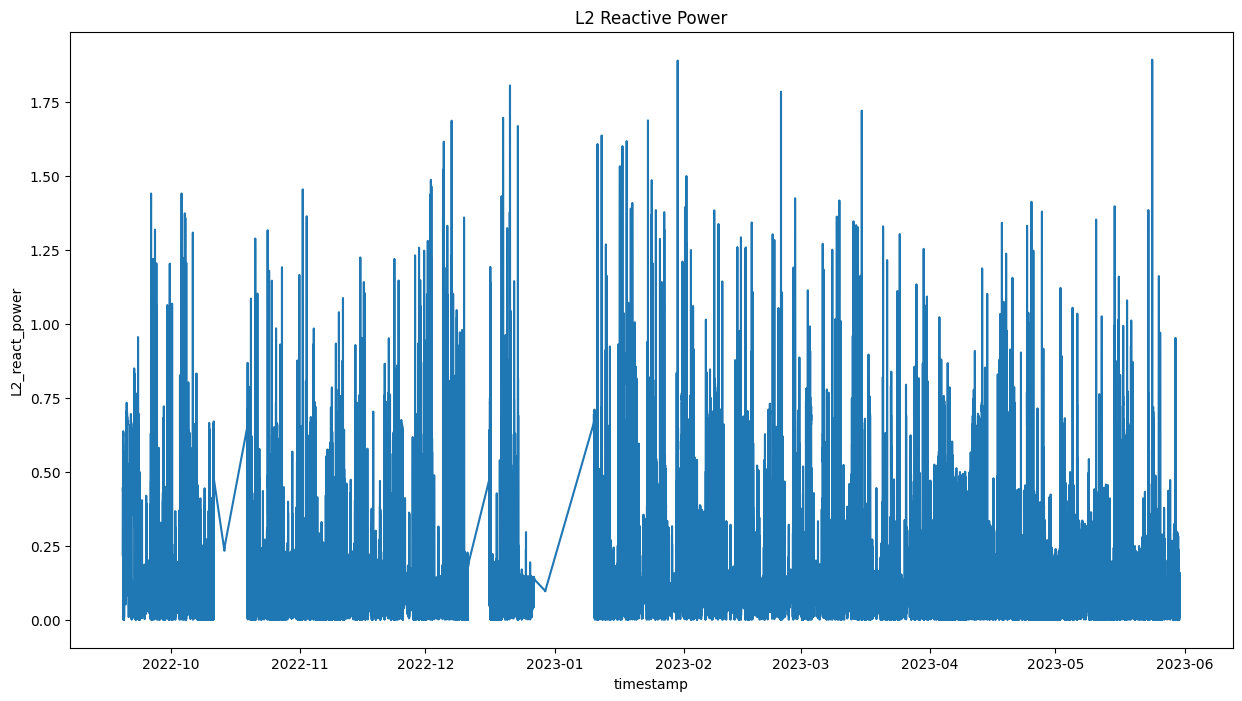

In [71]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_react_power')
    plt.title('L2 Reactive Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

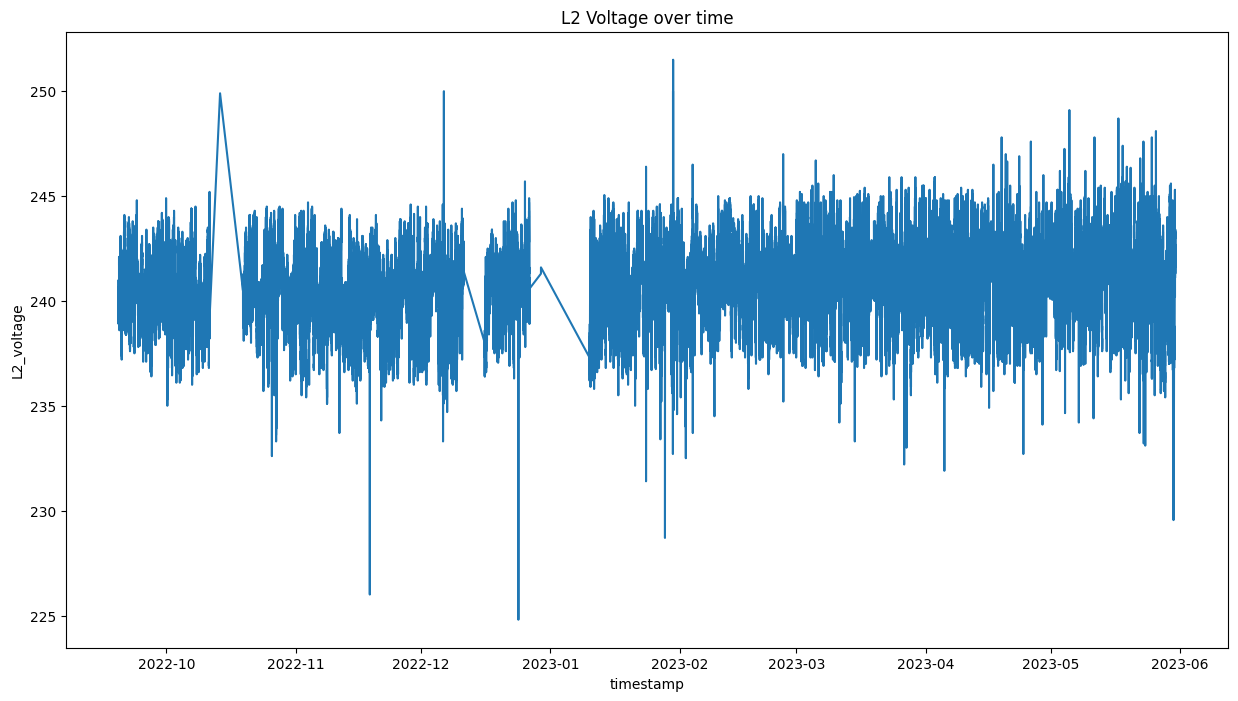

In [76]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_voltage')
    plt.title('L2 Voltage over time');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

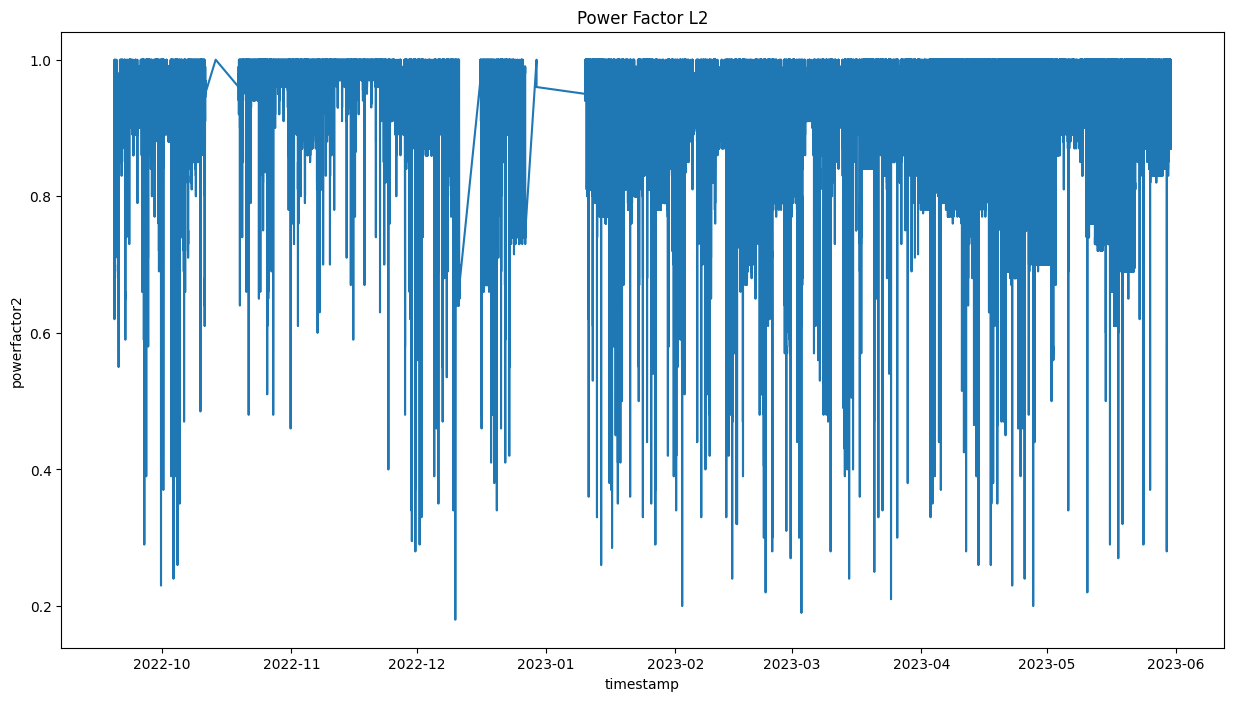

In [77]:
# Plot powerfactor2 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2')
    plt.title('Power Factor L2');

### L3 Phase Analysis

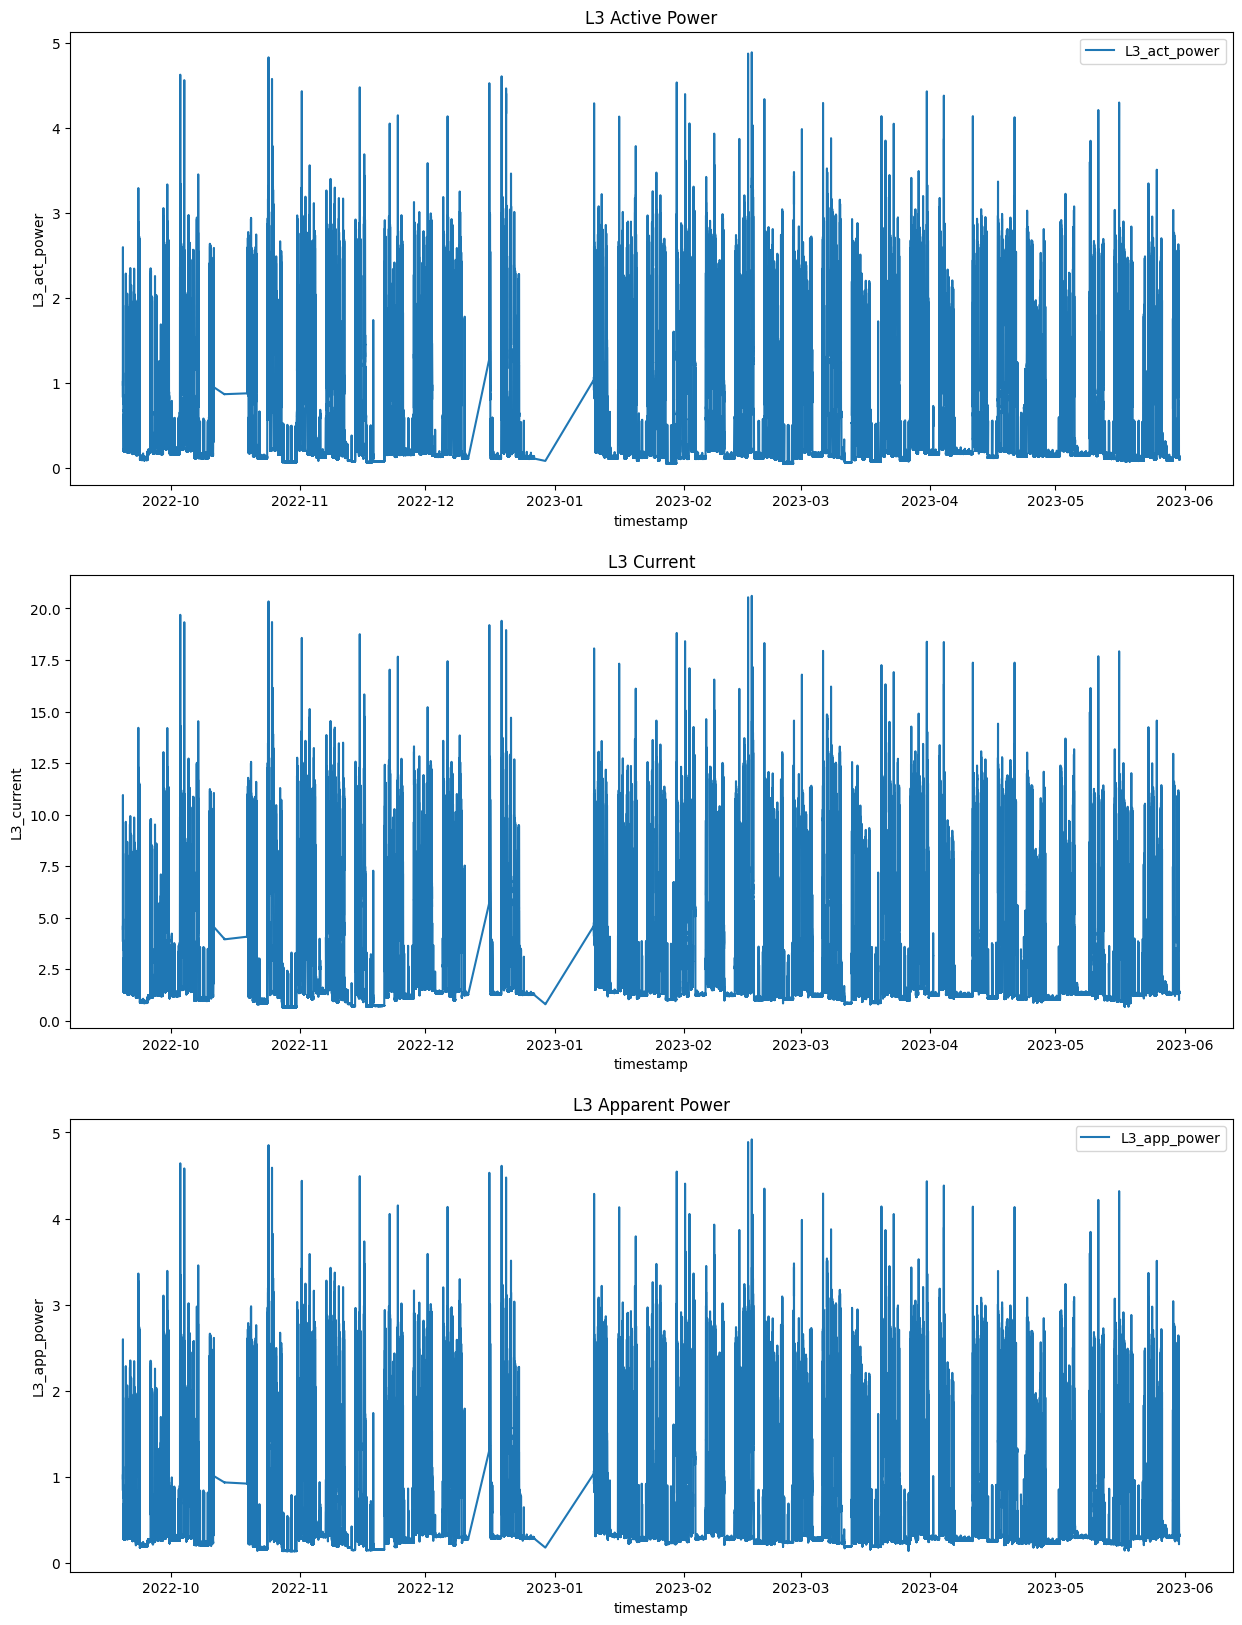

In [78]:
if df.columns.str.contains('L3').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))

    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3_act_power', ax=axes[0])
    axes[0].set_title('L3 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L3_current', ax=axes[1])
    axes[1].set_title('L3 Current')
    sns.lineplot(data=df, x='timestamp', y='L3_app_power', label='L3_app_power', ax=axes[2])
    axes[2].set_title('L3 Apparent Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

MemoryError: Unable to allocate 167. MiB for an array with shape (21886140,) and data type datetime64[ns]

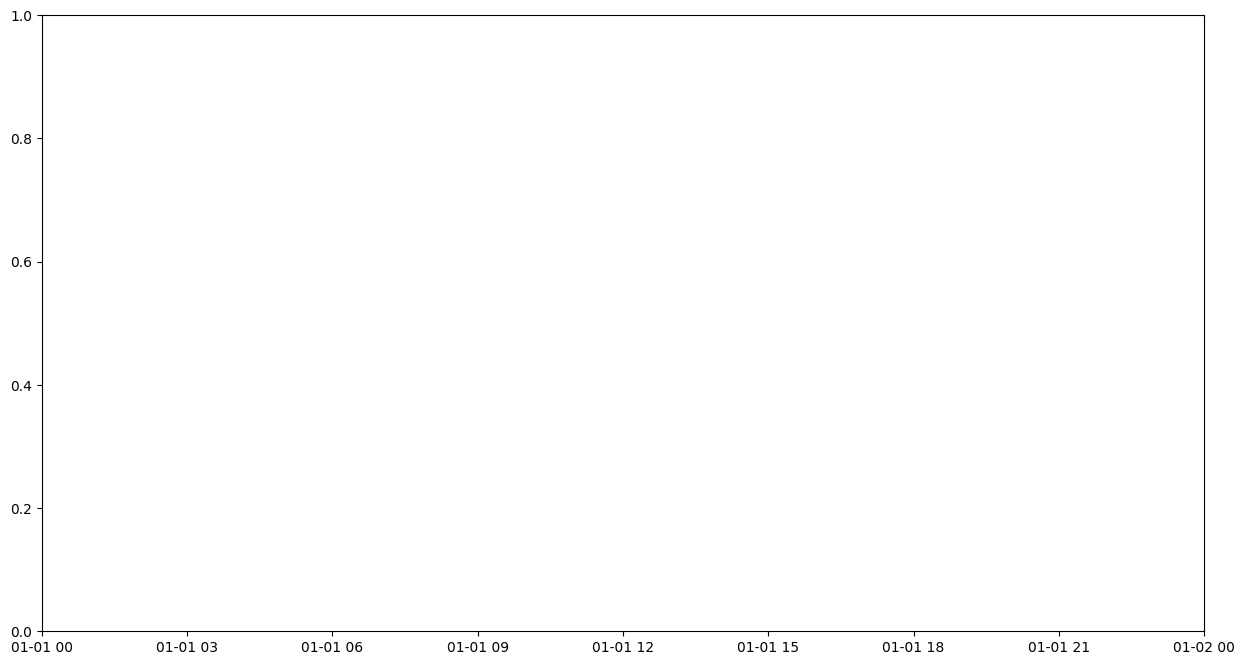

In [79]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_react_power')
    plt.title('L3 Reactive Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

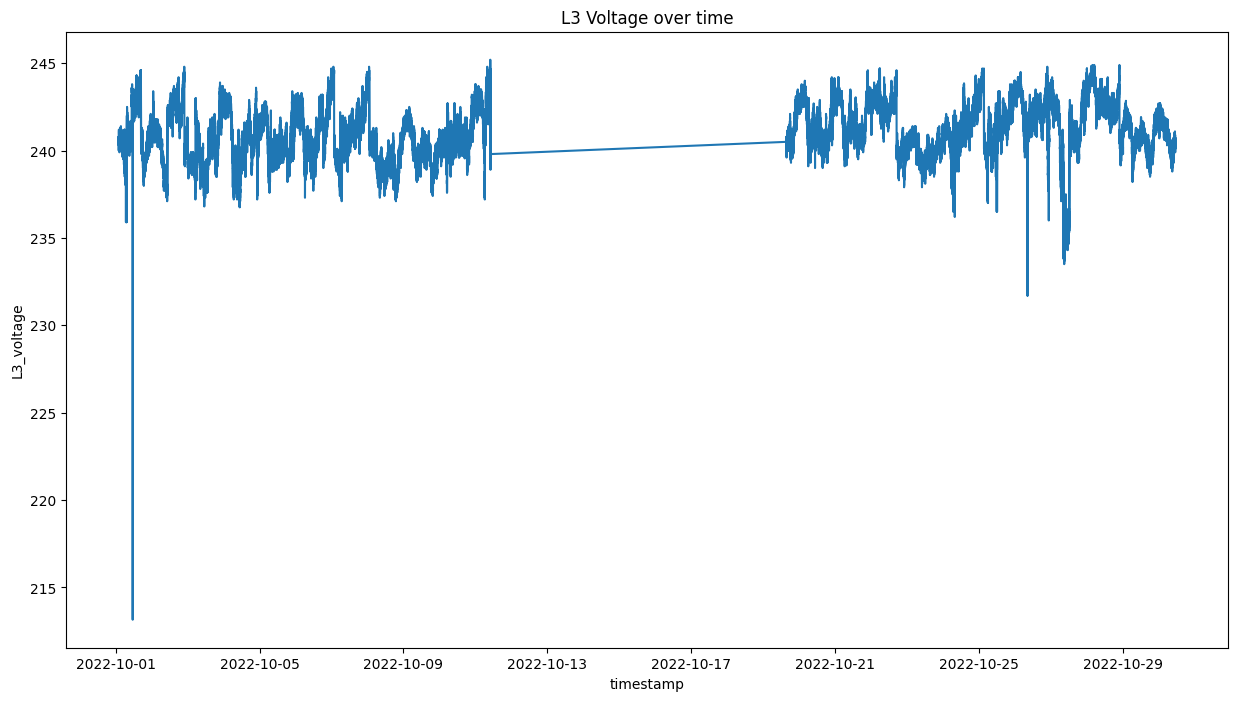

In [ ]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_voltage')
    plt.title('L3 Voltage over time');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

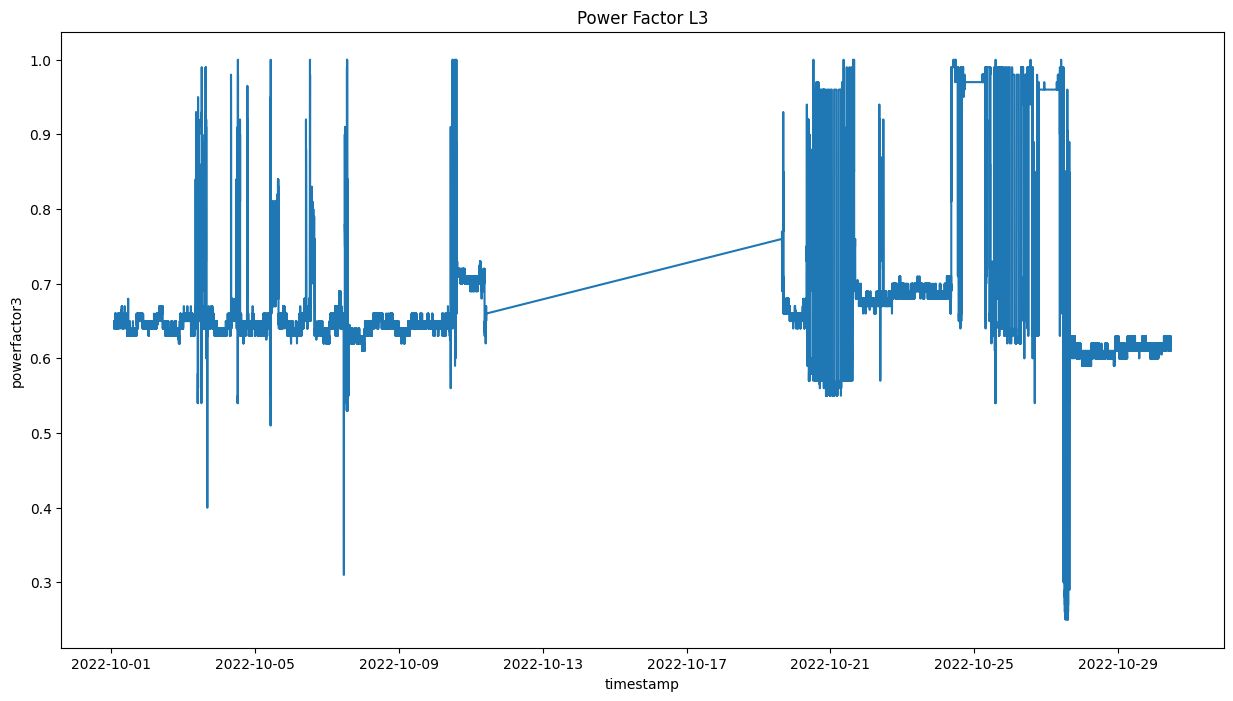

In [ ]:
# Plot powerfactor3 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3')
    plt.title('Power Factor L3');

### Grid Frequency Analysis

Text(0.5, 1.0, 'Grid Frequency')

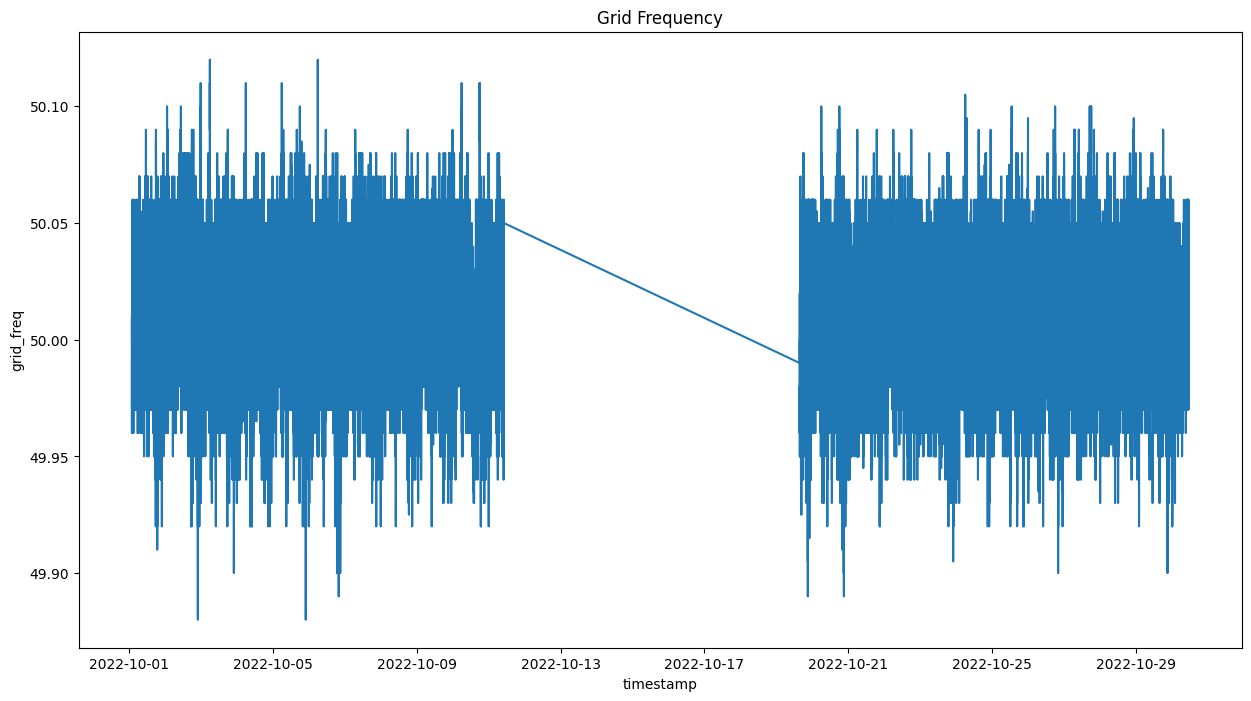

In [ ]:
sns.lineplot(data=df, x='timestamp', y='grid_freq')
plt.title('Grid Frequency')

## Cross-Phase Comparison (if available)

e:\DataScience\Mycroft\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


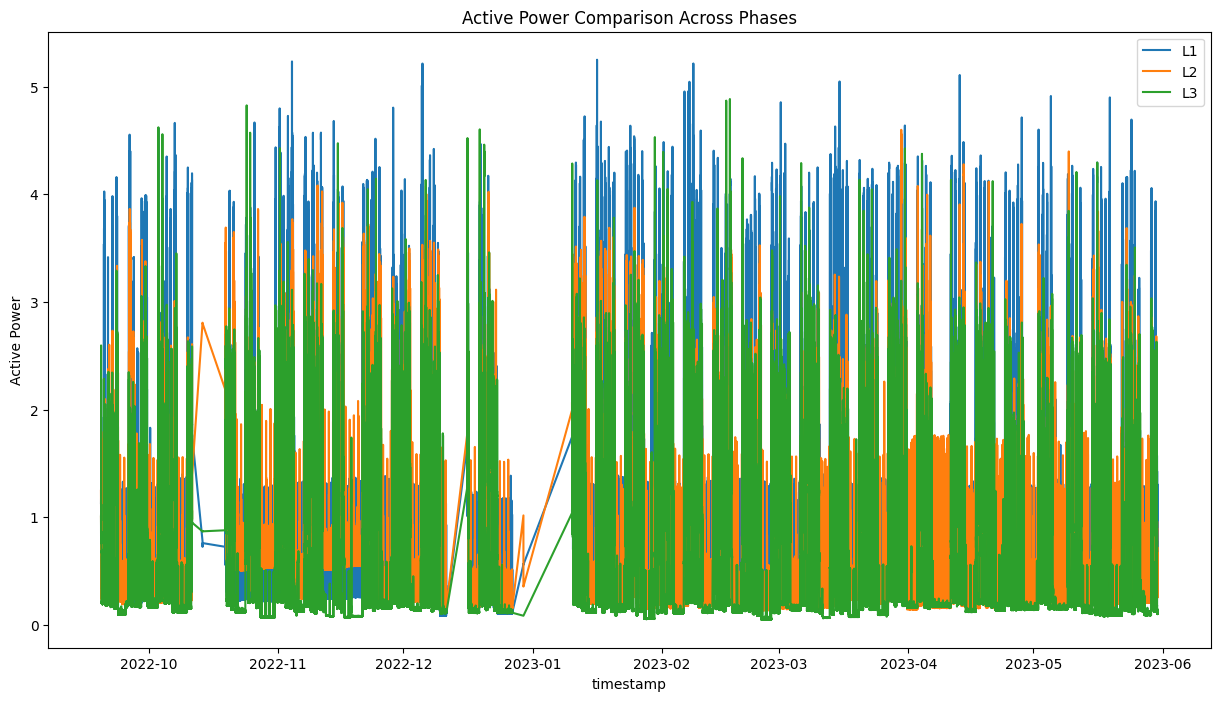

In [80]:
sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1')
if 'L2_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Active Power Comparison Across Phases')
plt.ylabel('Active Power')
plt.legend()
plt.show()

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_current', label='L1')
if 'L2_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_current', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_current', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Current Comparison Across Phases')
plt.ylabel('Current')
plt.legend()
plt.show()

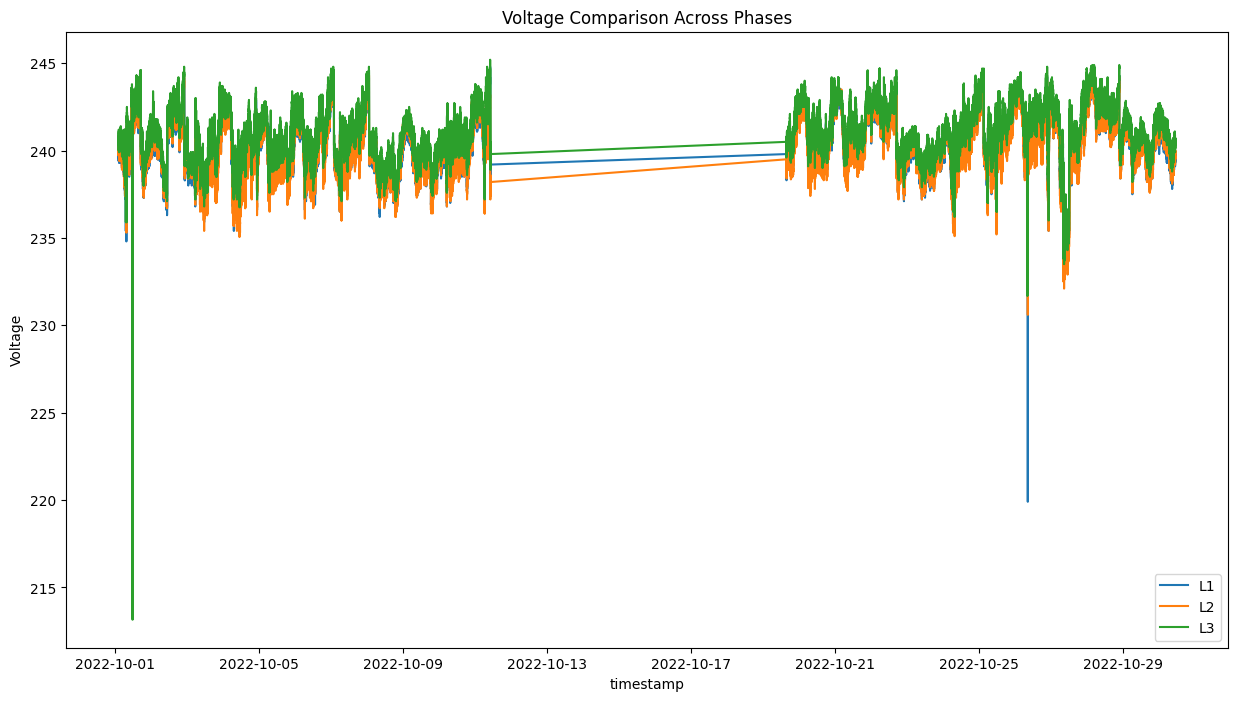

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage', label='L1')
if 'L2_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_voltage', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_voltage', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Voltage Comparison Across Phases')
plt.ylabel('Voltage')
plt.legend()
plt.show()

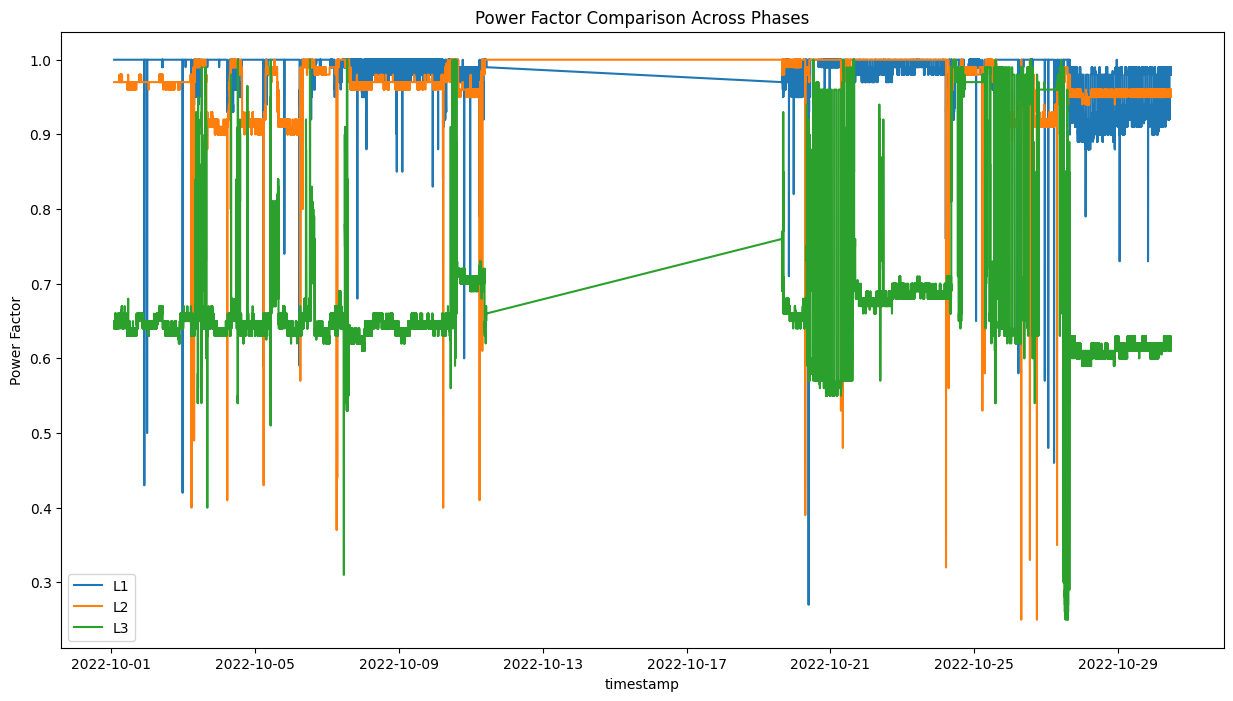

In [ ]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1', label='L1')
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Power Factor Comparison Across Phases')
plt.ylabel('Power Factor')
plt.legend()
plt.show()

## Hourly Analysis

In [ ]:
# Group by hour
df_hour = df.groupby(df['timestamp'].dt.floor('h'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_hour.indices.keys()).min(),
        pd.DatetimeIndex(df_hour.indices.keys()).max(), 
        freq='h'
    )
)

# Join with hourly aggregated data for each phase
l1_act_pow_hour_endog = full_range.join(df_hour['L1_act_power'].mean(), how='left').squeeze()
if 'L2_act_power' in df.columns:
    l2_act_pow_hour_endog = full_range.join(df_hour['L2_act_power'].mean(), how='left').squeeze()
if 'L3_act_power' in df.columns:
    l3_act_pow_hour_endog = full_range.join(df_hour['L3_act_power'].mean(), how='left').squeeze()

In [ ]:
df_hour.count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3,day_of_week,hour
count,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000,510.000000
mean,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824,2367.958824
std,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683,153.396683
min,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000,376.000000
25%,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000,2372.000000
50%,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000,2384.000000
75%,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
max,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000,3107.000000


In [ ]:
def plot_hourly_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.1]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

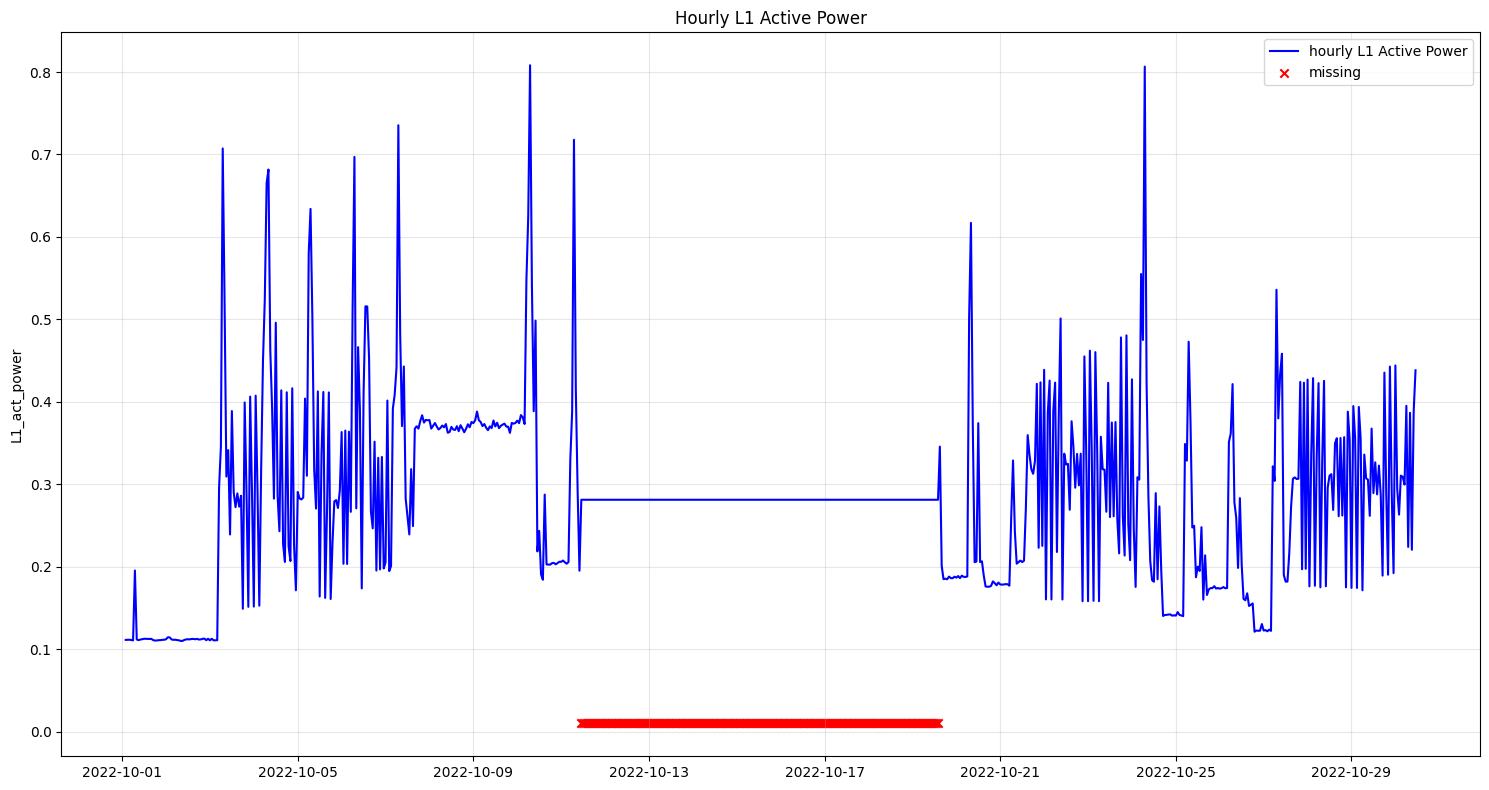

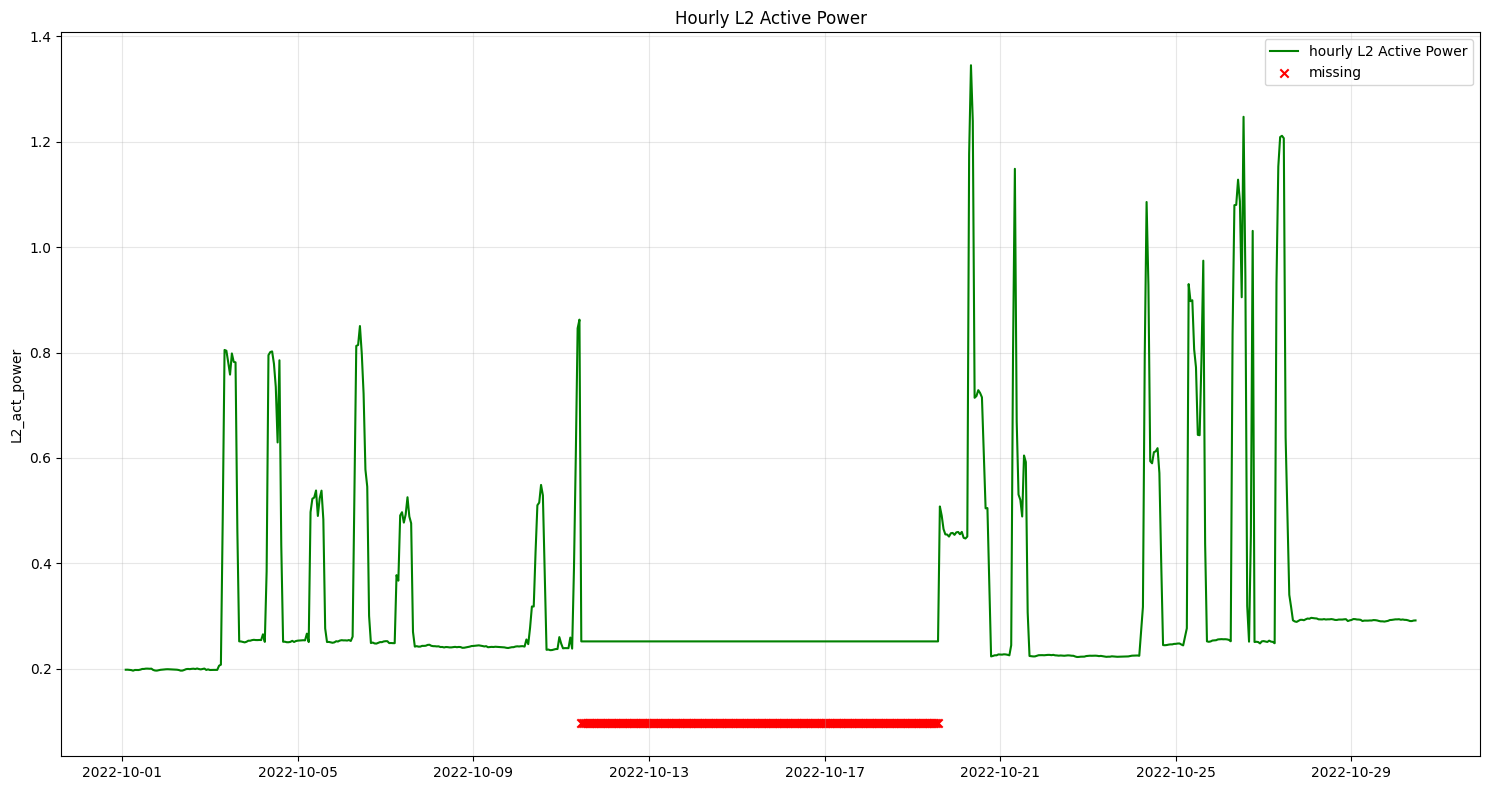

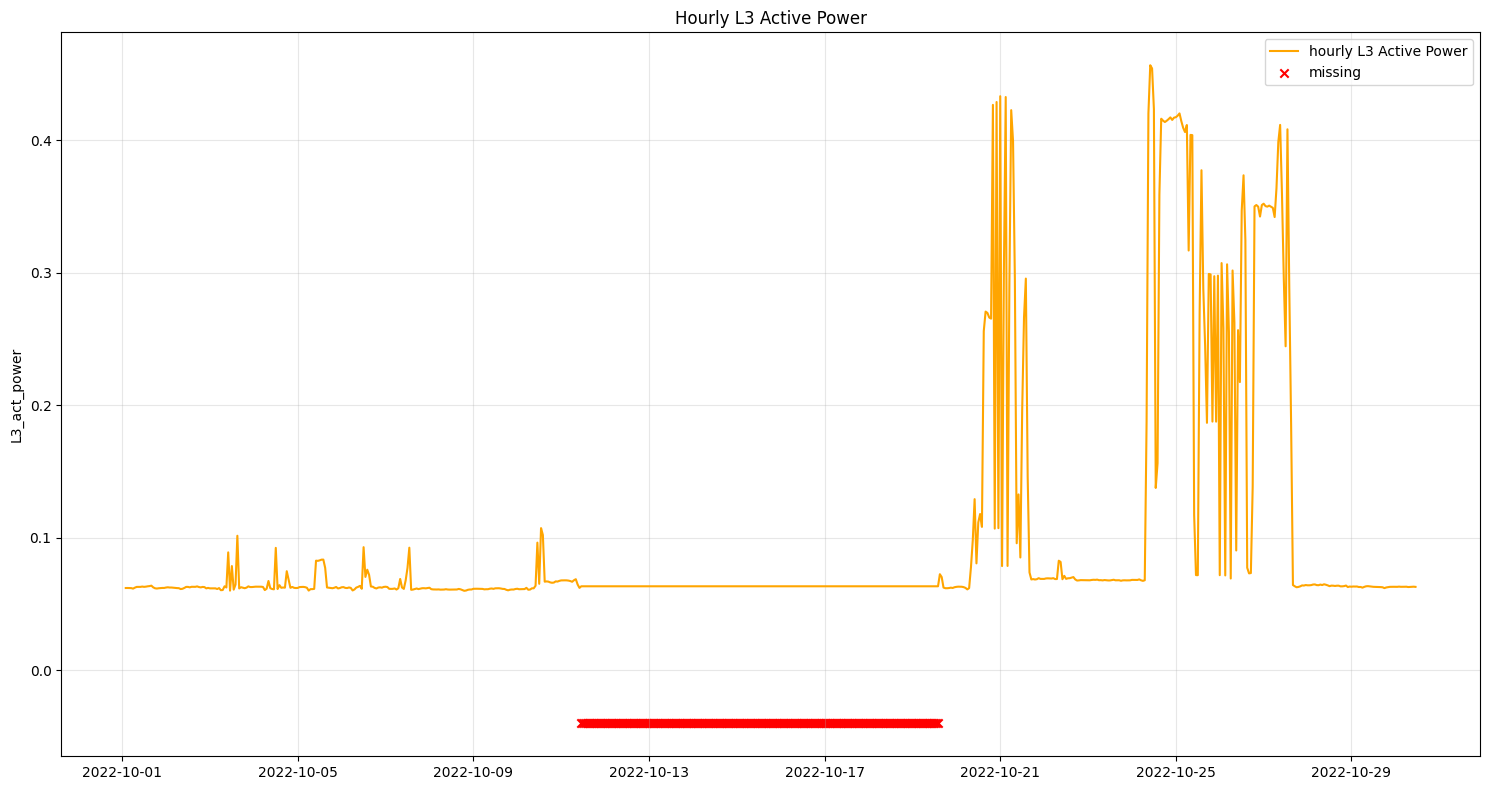

In [ ]:
plot_hourly_data(l1_act_pow_hour_endog, 'L1 Active Power')
plot_hourly_data(l2_act_pow_hour_endog, 'L2 Active Power', color='green')
plot_hourly_data(l3_act_pow_hour_endog, 'L3 Active Power', color='orange')

### Cross-phase

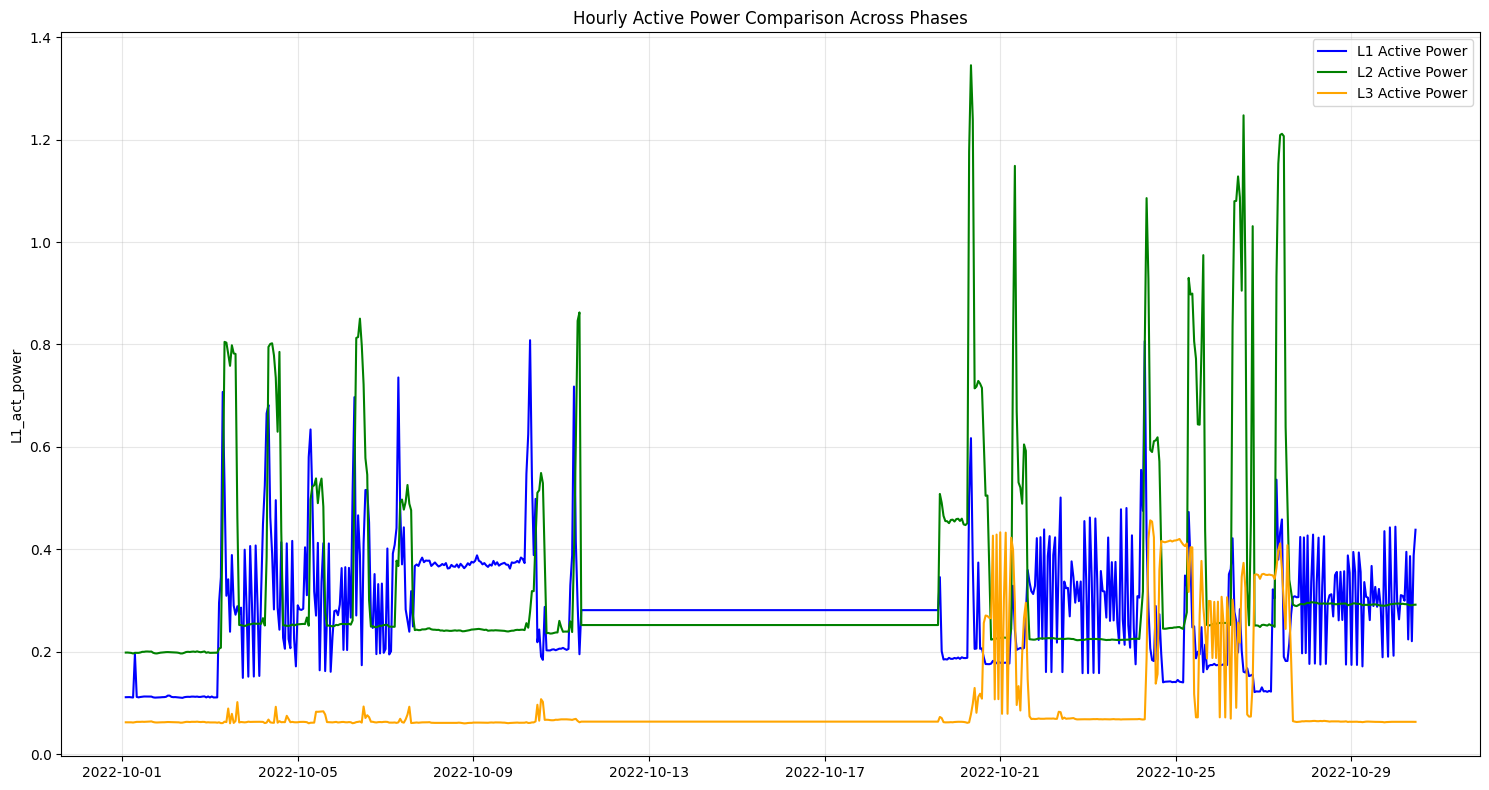

In [ ]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1), label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2), label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3), label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Cross-phase (smaller time range)

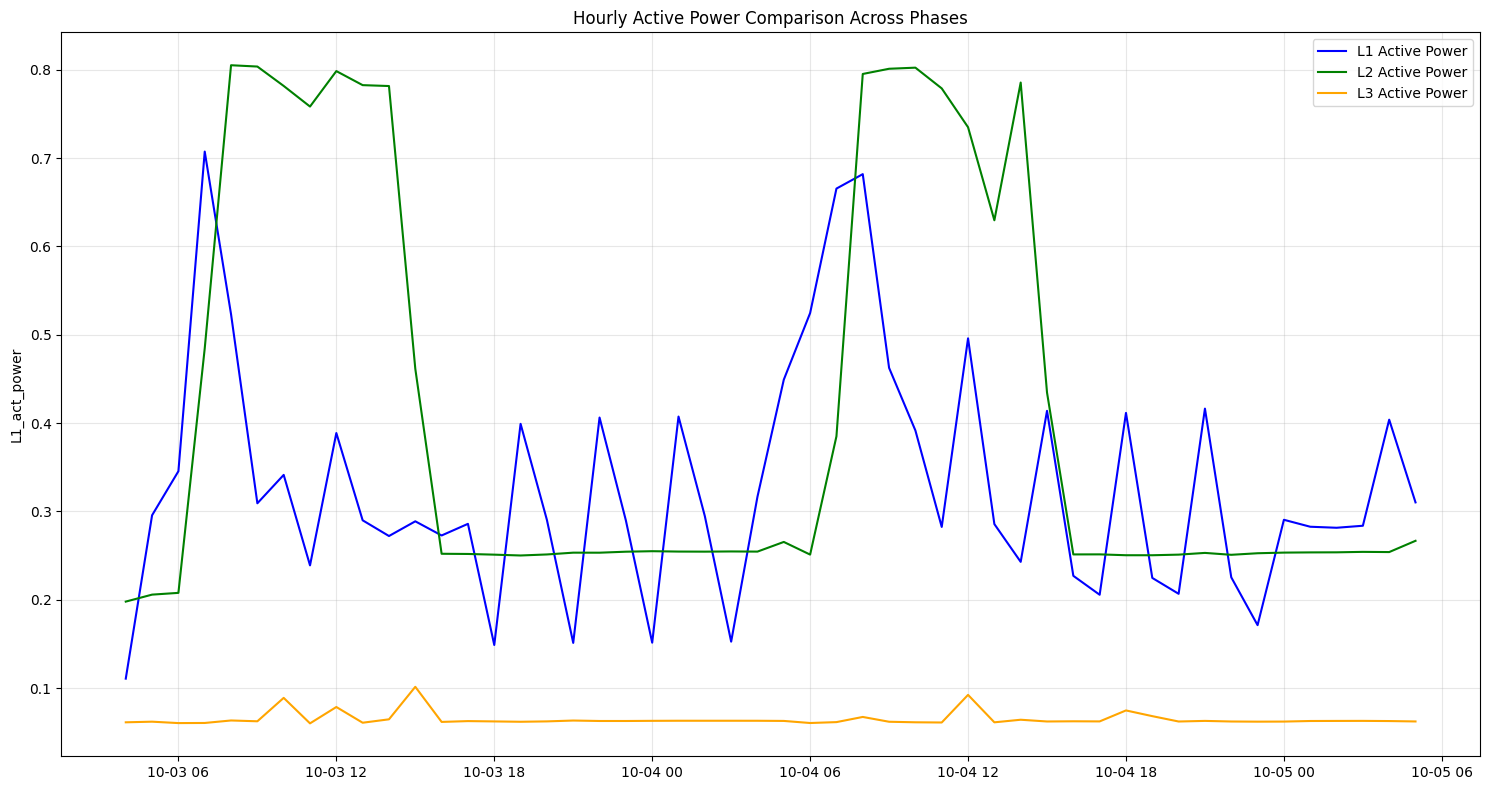

In [ ]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1).iloc[50:100], label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2).iloc[50:100], label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3).iloc[50:100], label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Weekly Patterns Analysis (based on hourly analysis)

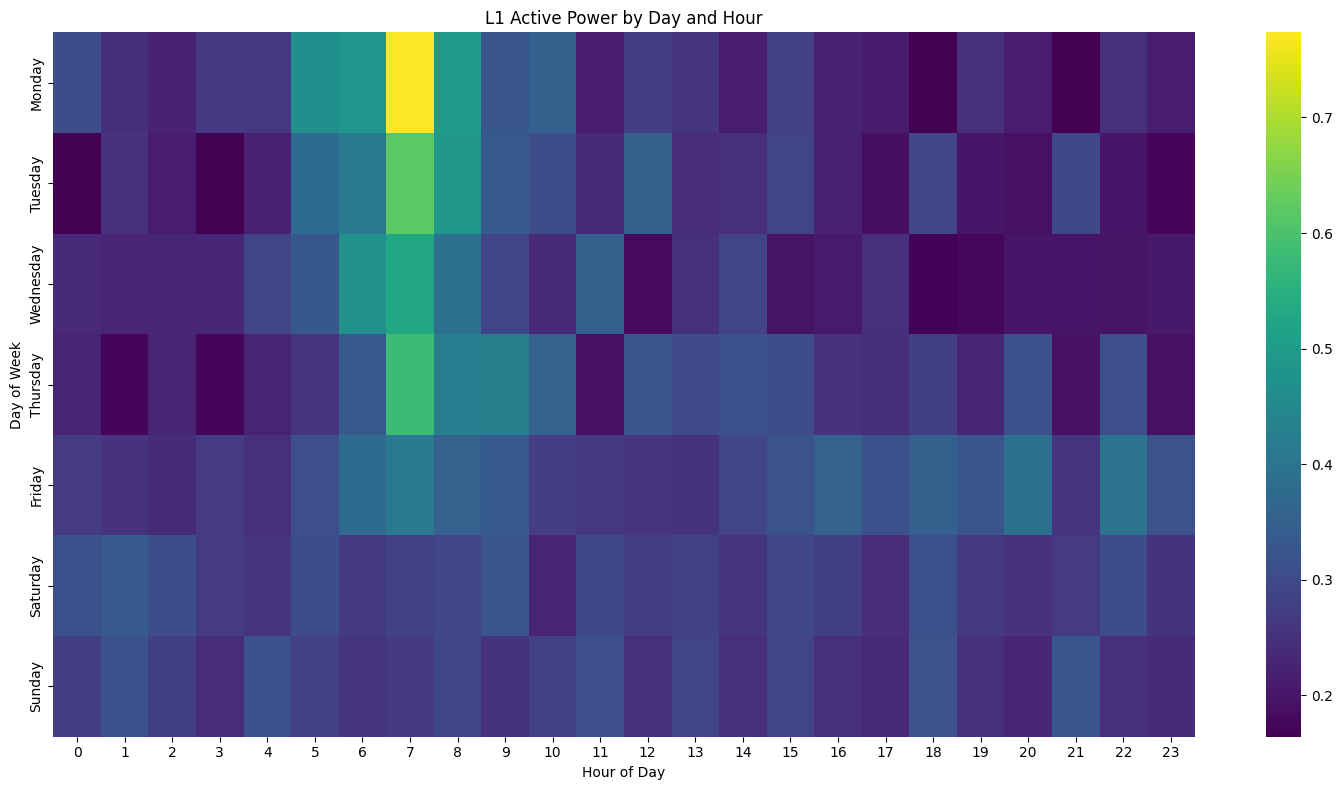

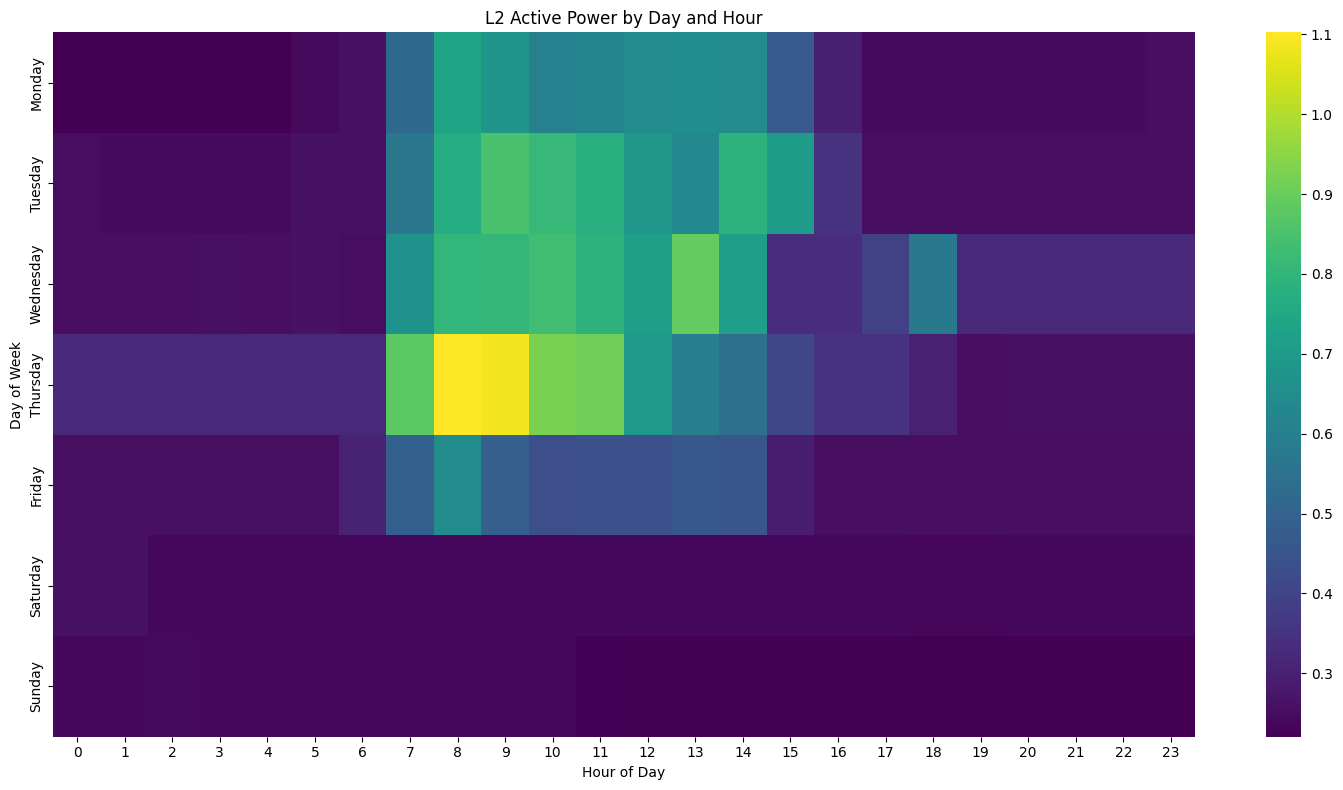

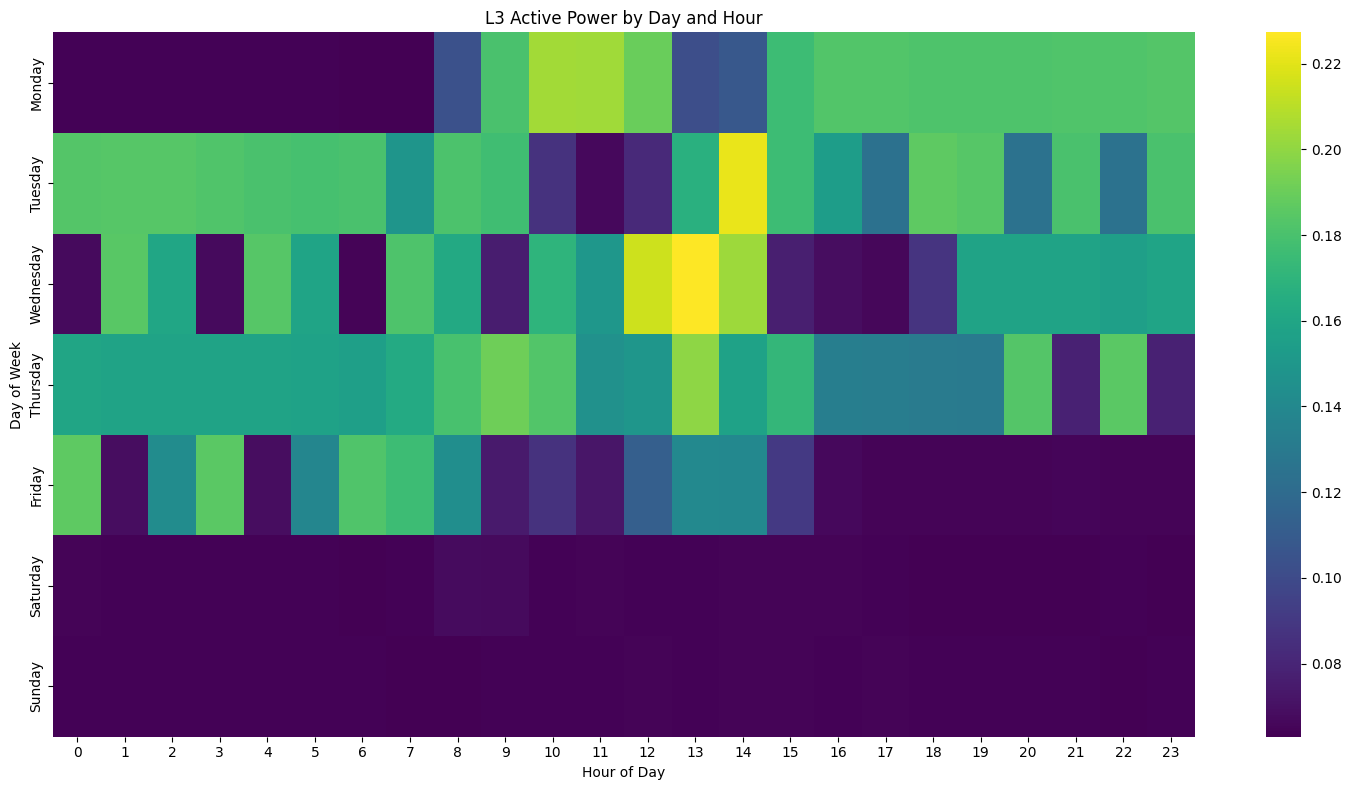

In [ ]:
# Extract day of week and hour
df['day_of_week'] = df['timestamp'].dt.day_name()
df['hour'] = df['timestamp'].dt.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'L1_act_power': 'mean',
    'L2_act_power': 'mean',
    'L3_act_power': 'mean'
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for L1
pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L1_act_power')
sns.heatmap(pivot_table, cmap='viridis', annot=False)
plt.title('L1 Active Power by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

if 'L2_act_power' in df.columns:
    # Plot heatmap for L2
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L2_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L2 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

if 'L3_act_power' in df.columns:
    # Plot heatmap for L3
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L3_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L3 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

## Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

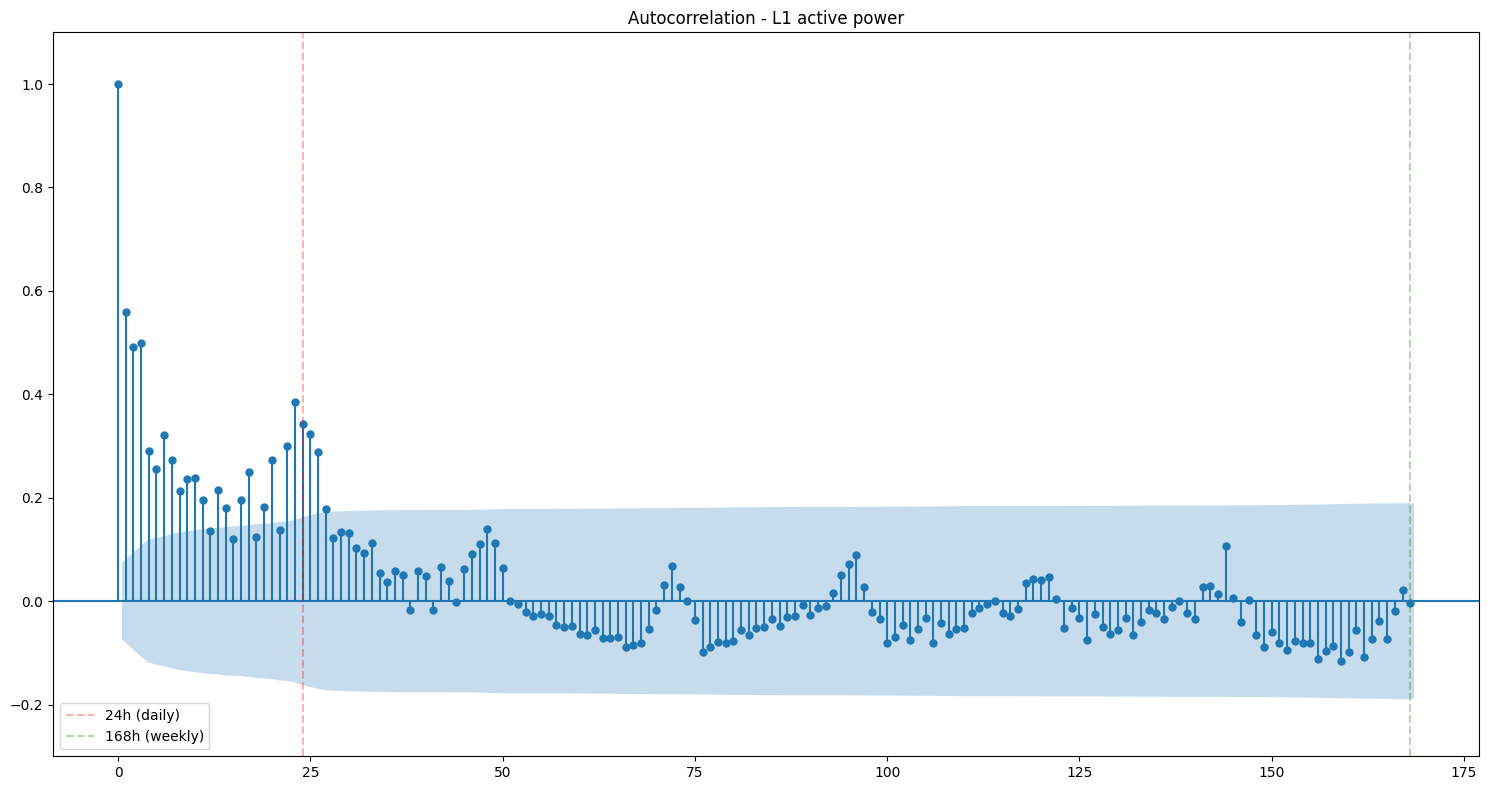

<Figure size 1500x600 with 0 Axes>

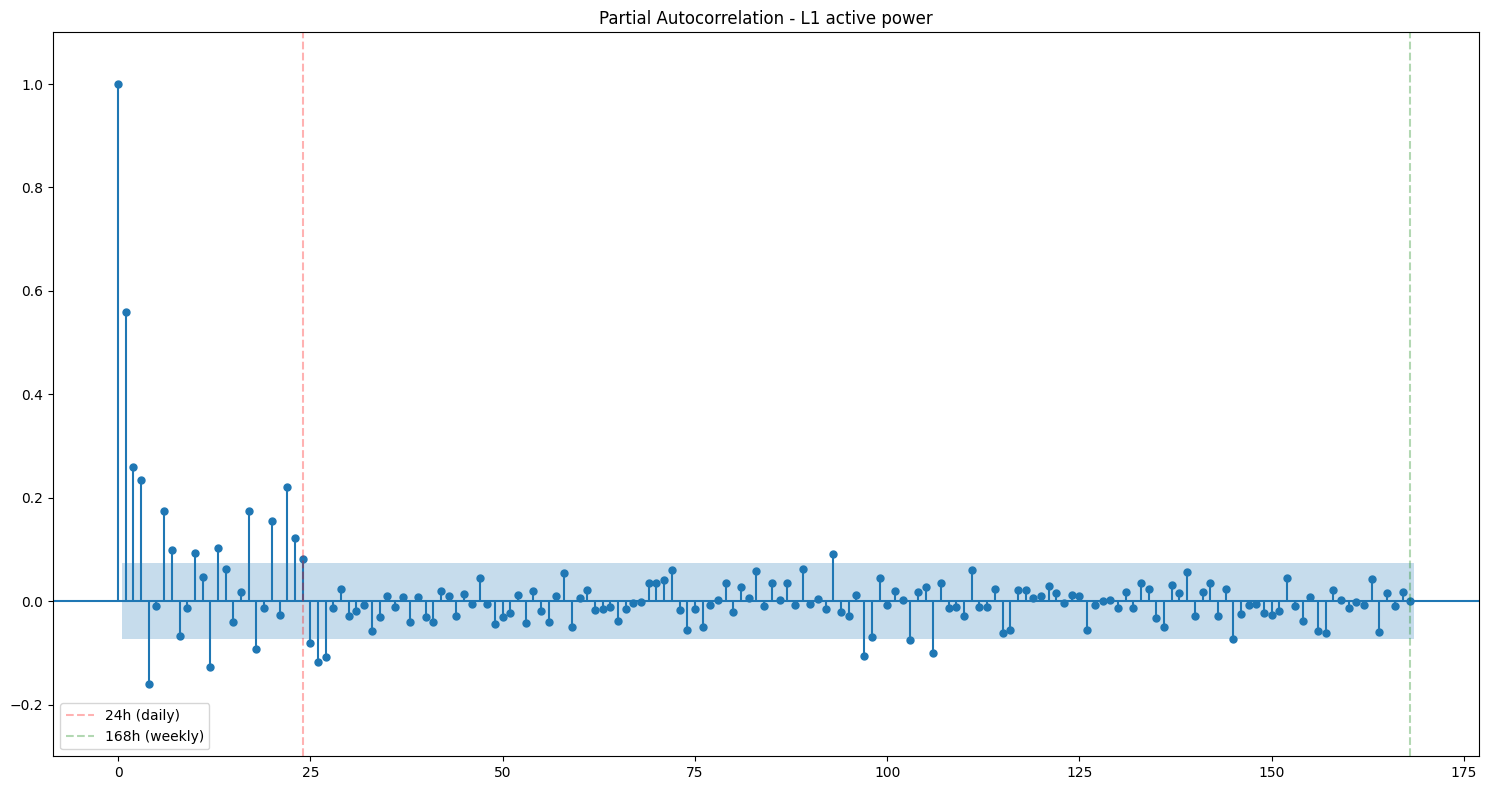

In [43]:
# Autocorrelation
plt.figure(figsize=(15, 6))
plot_acf(l1_act_pow_hour_endog.fillna(l1_act_pow_hour_endog.median()), lags=24*7, 
            title=f'Autocorrelation - L1 active power')
plt.ylim(-0.3, 1.1)
plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
plt.legend()
plt.tight_layout()
plt.show()

# Partial autocorrelation
plt.figure(figsize=(15, 6))
plot_pacf(l1_act_pow_hour_endog.fillna(l1_act_pow_hour_endog.median()), lags=24*7, 
            title=f'Partial Autocorrelation - L1 active power')
plt.ylim(-0.3, 1.1)
plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
plt.legend()
plt.tight_layout()
plt.show()